# SparkEV – Module 2: Federated Learning for Charging Recommendation

Companion to `01_charging_recommendation.ipynb`. It reuses that notebook's data loading, feature engineering, targets, chronological split and metric helpers **unchanged**, and adds federated training for the models where FL is valid.

| Component | Federated here? | Reason |
|---|---|---|
| **Model A** – A1 demand regression, A2 q85 quantile (→ target SoC), A3 level band | **Yes** | Features and targets come from one user's own sessions, so a user is a natural client |
| **Model B** – urgency (3-class) | **Yes** | Same reason |
| **Model C** – site congestion | **No** | Target is built by pooling all users at a site; a user cannot compute it. Matches persistence at 1 h, so FL adds nothing |
| **Decision layer** | **No** | Hand-set rules, no trained parameters. It runs on the device and consumes the model outputs |
| **Explainability (SHAP, Section 16)** | **Post-hoc, no training** | Opens the trained Model A / B networks and attributes each prediction to its features – globally, per session, and in a federated (client-local) variant |

**What changes versus Module 2**
- **Model family:** HistGradientBoosting has no weights to average, so the federated models are small MLPs (written in NumPy, no PyTorch/Flower needed). A centralised HGB with fixed parameters is kept as a reference row.
- **Clients:** one client = one `user_id`. Raw sessions never leave the client; the server only sees model weights and a few aggregate statistics (feature sums for scaling, class counts).
- **Methods compared on the same test rows:** centralised MLP, local-only MLP, **FedAvg**, **FedProx**, **FedPer** (shared body, personal output layer).
- **Splits:** each client splits *its own* sessions chronologically, 70/15/15 (first 70 % train, next 15 % validation, last 15 % test). Module 2's single pooled calendar split cannot be used on this data: users join at different times between 2018 and 2021 (median active span about 7 months), so one shared cut-off leaves almost every user without data in at least one split. As a result the test rows are **not** the same rows as in Module 2; compare methods *within this notebook* (all methods, the baselines and the HGB reference use identical rows). The validation split picks the best round / epoch and the deployed method per task; there is no train+val refit.
- **Cold start:** a second experiment holds out whole users to measure how a new user is served by the global model.

Users with too little data in any split (see `CFG.min_*`) cannot train or be evaluated locally and are dropped; the notebook prints how many.

⏱ Full run: about 15 minutes on one CPU. Set `QUICK = True` for a fast smoke test.

## Training improvements

The first version of this notebook trained for 40 communication rounds. Each user has only about 80 training sessions, so every round gave each client about 4 optimiser steps: about 160 steps in total, against about 14,000 for the centralised MLP. The validation score was still improving at round 40, so the federated models were **under-trained**, not limited by federation. Three changes fix this. All of them were chosen on the **validation split**; the test rows were not used for any choice.

| Change | Setting | Why |
|---|---|---|
| Longer training | `rounds=150`, validation check every 5 rounds | the best round is now inside the budget instead of at its end |
| FedAdam server optimiser (Reddi et al., 2021) | `server_opt="adam"`, `server_lr=0.01` | the averaged client update is used as a pseudo-gradient for Adam on the server; this converges faster and more stably on very different (non-IID) users than plain averaging |
| Anchored target for A1 and A2 | `anchor_tasks=("A1", "A2")` | the network predicts the difference from the user's own historical mean need, and the mean is added back inside the model (`Predictor.out`); every user starts from a sensible personal baseline. The centralised and local-only MLPs use exactly the same setup, so the comparison stays fair |

What was tried and **not** kept, because it was worse on validation: 5 local epochs per round (more client drift) and FedPer for the regression tasks.

**Effect on the test set** (same rows, same metrics):

| Task, metric | First version (FedAvg) | This version (FedAvg) | Centralised MLP | Simple baseline |
|---|---|---|---|---|
| A1 next-charge need, R² | −0.203 | **0.236** | 0.249 | 0.218 (user mean) |
| A2 q85 need, pinball loss (lower is better) | 6.696 | **4.927** | 4.542 | 4.963 (user q90) |
| B urgency, macro-F1 | 0.610 | **0.636** | 0.660 | 0.465 (user history) |
| A1 new users (cold start), R² | −0.433 | **0.247** | 0.218 | 0.254 (user mean) |

The **deployed** federated model of each task is the method with the best validation score (Section 13): FedAvg for A1 and A2, FedPer for A3 and B.

**Cost:** longer training means more communication: about 15.7 MB per client over the whole training, instead of about 4.2 MB (Section 15).

## 0. Setup

In [1]:
import json, os, time, warnings
from types import SimpleNamespace
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, balanced_accuracy_score, f1_score,
                             confusion_matrix, classification_report, mean_pinball_loss)

try:
    from IPython.display import display, Image
except ImportError:                      # plain-Python fallback
    display, Image = print, (lambda p: p)

warnings.filterwarnings("ignore")
RNG = 42
CHARGE_EFF = 0.88          # energy_session -> energy stored (derived from Dataset 3)
RESERVE_PCT = 15           # safety reserve used to define the "needed" charge level
SOC_MAX = 95               # dataset charges to 95 %

LEVEL_BINS = [-1, 50, 70, 85, 100]
LEVEL_NAMES = ["Top-up (<=50%)", "Moderate (50-70%)", "High (70-85%)", "Near-full (85-95%)"]
URG_BINS = [0, 1.5, 4, 1e12]
URG_NAMES = ["Time-critical", "Moderate", "Flexible"]

DATA_DIR = os.path.join("..", "..", "data", "raw")   # folder containing the CSV files
OUT_DIR = "./module2_fl_outputs"     # separate from module2_outputs so nothing is overwritten
os.makedirs(OUT_DIR, exist_ok=True)

QUICK = False        # True = tiny run just to check that everything executes
RUN_COLD_START = True

CFG = SimpleNamespace(
    rounds=150,             # communication rounds (40 stopped training while it was still improving)
    local_epochs=2,         # epochs each client trains per round
    batch=64, lr=3e-3,      # local Adam optimiser (state reset every round)
    hidden=(64, 32),        # MLP hidden layers
    client_frac=1.0,        # fraction of clients sampled per round
    prox_mu=0.01,           # FedProx proximal strength
    n_personal=1,           # FedPer: number of final layers kept personal
    eval_every=5,           # validation check every N rounds (best round is kept)
    server_opt="adam",      # "avg" = plain FedAvg averaging, "adam" = FedAdam server optimiser
    server_lr=0.01,         # FedAdam server learning rate
    server_betas=(0.9, 0.99), server_tau=1e-3,
    anchor_tasks=("A1", "A2"),  # regression tasks that predict the change from the user's own mean need
    local_only_epochs=30,   # per-client epochs for the local-only baseline
    central_epochs=40,      # epochs for the centralised MLP
    min_train=20, min_val=4, min_test=4,   # minimum sessions per client and split
    cold_frac=0.2,          # share of users held out for the cold-start experiment
    class_weight_power=0.5, # 0 = unweighted cross-entropy, 1 = fully balanced
    seed=RNG)
if QUICK:
    CFG.rounds, CFG.eval_every, CFG.local_only_epochs, CFG.central_epochs = 4, 2, 3, 3

## 1. Load + clean, features, splits, metrics  (copied unchanged from Module 2)

In [2]:
def load(data_dir):
    rd = lambda f: pd.read_csv(os.path.join(data_dir, f), sep=";", decimal=",", na_values=["NA"])
    d1 = rd("Dataset1_charging_reports.csv")
    d2 = rd("Dataset2_user_predictions.csv")
    d3 = rd("Dataset3_session_predictions.csv")
    return d1, d2, d3


def build_sessions(d1, d2, d3):
    m = d1.merge(d3, on=["user_id", "session_id"], how="inner").merge(d2, on="user_id", how="left")
    m = m.dropna(subset=["plugout_time", "charging_time", "battery_capacity", "charging_power"]).copy()
    m["pt"] = pd.to_datetime(m["plugin_time"])
    m["po"] = pd.to_datetime(m["plugout_time"])
    m = m.sort_values(["user_id", "pt"]).reset_index(drop=True)
    m["slack"] = m["connection_time"] / m["charging_time"]          # dwell / needed charging time
    return m


def add_features(m):
    g = m.groupby("user_id", sort=False)
    m["hour"] = m.pt.dt.hour
    m["dow"] = m.pt.dt.dayofweek
    m["month"] = m.pt.dt.month
    m["weekend"] = (m.dow >= 5).astype(int)
    m["hour_sin"] = np.sin(2 * np.pi * m.hour / 24)
    m["hour_cos"] = np.cos(2 * np.pi * m.hour / 24)
    m["loc_code"] = m["location"].astype("category").cat.codes
    m["cur_soc_need"] = m["SoC_diff"]                 # % battery being charged now (from arrival SoC)
    m["cur_energy"] = m["energy_session"]
    m["cur_charge_time"] = m["charging_time"]

    # --- user history (strictly past sessions) ---
    for k in (1, 2, 3):
        m[f"soc_lag{k}"] = g["SoC_diff"].shift(k)
    m["soc_hist_mean"] = g["SoC_diff"].transform(lambda s: s.shift(1).expanding().mean())
    m["soc_hist_std"] = g["SoC_diff"].transform(lambda s: s.shift(1).expanding().std())
    m["soc_roll5"] = g["SoC_diff"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
    m["soc_hist_dow_mean"] = m.groupby(["user_id", "dow"])["SoC_diff"].transform(
        lambda s: s.shift(1).expanding().mean())
    m["n_prev"] = g.cumcount()
    prev_po = g["po"].shift(1)
    m["hrs_since_prev_plugout"] = (m.pt - prev_po).dt.total_seconds() / 3600
    m["conn_lag1"] = g["connection_time"].shift(1)
    m["conn_hist_mean"] = g["connection_time"].transform(lambda s: s.shift(1).expanding().mean())
    m["conn_hist_med"] = g["connection_time"].transform(lambda s: s.shift(1).expanding().median())
    m["conn_hist_dow_mean"] = m.groupby(["user_id", "dow"])["connection_time"].transform(
        lambda s: s.shift(1).expanding().mean())
    m["conn_hist_hour_mean"] = m.groupby(["user_id", "hour"])["connection_time"].transform(
        lambda s: s.shift(1).expanding().mean())
    # habit features: what happened after this user's previous plug-ins on the same weekday / hour
    m["gap_prev_days"] = (m.pt - g["pt"].shift(1)).dt.total_seconds() / 86400
    m["_next_gap"] = (g["pt"].shift(-1) - m.pt).dt.total_seconds() / 86400
    m["_next_soc"] = g["SoC_diff"].shift(-1)
    m["gap_hist_mean"] = g["gap_prev_days"].transform(lambda s: s.expanding().mean())
    m["gap_hist_med"] = g["gap_prev_days"].transform(lambda s: s.expanding().median())
    m["after_dow_gap_mean"] = m.groupby(["user_id", "dow"])["_next_gap"].transform(lambda s: s.shift(1).expanding().mean())
    m["after_dow_soc_mean"] = m.groupby(["user_id", "dow"])["_next_soc"].transform(lambda s: s.shift(1).expanding().mean())
    m["after_dow_soc_med"] = m.groupby(["user_id", "dow"])["_next_soc"].transform(lambda s: s.shift(1).expanding().median())
    m["after_hour_soc_mean"] = m.groupby(["user_id", "hour"])["_next_soc"].transform(lambda s: s.shift(1).expanding().mean())
    m["after_soc_mean"] = g["_next_soc"].transform(lambda s: s.shift(1).expanding().mean())
    m["soc_hist_med"] = g["SoC_diff"].transform(lambda s: s.shift(1).expanding().median())
    m["soc_hist_q75"] = g["SoC_diff"].transform(lambda s: s.shift(1).expanding().quantile(0.75))
    m["soc_hist_q90"] = g["SoC_diff"].transform(lambda s: s.shift(1).expanding().quantile(0.90))
    m["soc_per_day_hist"] = m["soc_hist_mean"] / m["gap_hist_mean"].clip(lower=0.1)
    m["slack_lag1"] = g["slack"].shift(1)
    m["slack_hist_med"] = g["slack"].transform(lambda s: s.shift(1).expanding().median())
    m["hist_hour_mean"] = g["hour"].transform(lambda s: s.shift(1).expanding().mean())

    # --- targets ---
    m["next_soc_need"] = g["SoC_diff"].shift(-1)                       # demand until next charge
    m["next_gap_days"] = (g["pt"].shift(-1) - m.pt).dt.total_seconds() / 86400
    m["target_level_soc"] = np.clip(m.next_soc_need + RESERVE_PCT, 0, SOC_MAX)
    m["level_class"] = pd.cut(m.target_level_soc, LEVEL_BINS, labels=False)
    m["urg_class"] = pd.cut(m.slack, URG_BINS, labels=False, right=False)
    return m


FEATS_COMMON = ["hour", "dow", "month", "weekend", "hour_sin", "hour_cos", "loc_code",
                "battery_capacity", "charging_power", "cur_soc_need", "cur_energy",
                "cur_charge_time", "n_prev", "hrs_since_prev_plugout", "hist_hour_mean"]
FEATS_A = FEATS_COMMON + ["soc_lag1", "soc_lag2", "soc_lag3", "soc_hist_mean", "soc_hist_std",
                          "soc_roll5", "soc_hist_dow_mean", "conn_hist_mean", "gap_prev_days", "gap_hist_mean",
                          "gap_hist_med", "after_dow_gap_mean", "after_dow_soc_mean", "after_dow_soc_med",
                          "after_hour_soc_mean", "after_soc_mean", "soc_hist_med", "soc_hist_q75",
                          "soc_hist_q90", "soc_per_day_hist"]
FEATS_B = FEATS_COMMON + ["conn_lag1", "conn_hist_mean", "conn_hist_med", "conn_hist_dow_mean",
                          "conn_hist_hour_mean", "slack_lag1", "slack_hist_med", "soc_hist_mean"]


def chrono_split(df, col="pt", fr=(0.70, 0.15)):
    """Chronological split (no shuffling) -> honest estimate of future performance."""
    c1 = df[col].quantile(fr[0]); c2 = df[col].quantile(fr[0] + fr[1])
    return df[df[col] <= c1], df[(df[col] > c1) & (df[col] <= c2)], df[df[col] > c2]


def reg_metrics(y, p):
    return dict(MAE=float(mean_absolute_error(y, p)),
                RMSE=float(np.sqrt(mean_squared_error(y, p))),
                R2=float(r2_score(y, p)))


def cls_metrics(y, p, names):
    out = dict(accuracy=float(accuracy_score(y, p)),
               balanced_accuracy=float(balanced_accuracy_score(y, p)),
               macro_F1=float(f1_score(y, p, average="macro")),
               weighted_F1=float(f1_score(y, p, average="weighted")),
               within_one_class_accuracy=float((np.abs(np.asarray(y) - np.asarray(p)) <= 1).mean()))
    out["confusion_matrix"] = confusion_matrix(y, p, labels=range(len(names))).tolist()
    out["per_class"] = classification_report(y, p, labels=range(len(names)), target_names=names,
                                             output_dict=True, zero_division=0)
    return out

## 2. Federated data layer

- **Task frames** reproduce Module 2's filtering for A and B exactly.
- **Per-client chronological split:** each client orders its own sessions by plug-in time and keeps the first 70 % for training, the next 15 % for validation and the last 15 % for testing. Nothing about other clients' timelines is needed.
- **Federated scaler:** each client sends only per-feature counts, sums and sums of squares of its *training* rows; the server turns these into one mean/std. NaNs (early-history rows) become 0 after scaling plus a "was missing" flag. `loc_code` is replaced by a one-hot over a fixed list of sites, so every client uses the same encoding.
- **Cross-user fairness:** every client keeps its own train / validation / test rows.

In [3]:
TASKS = {
    "A1": dict(data="A", kind="reg",   ycol="next_soc_need", scale=100.0),
    "A2": dict(data="A", kind="quant", ycol="next_soc_need", scale=100.0, q=0.85),
    "A3": dict(data="A", kind="cls",   ycol="level_class", n_classes=4, names=LEVEL_NAMES),
    "B":  dict(data="B", kind="cls",   ycol="urg_class",   n_classes=3, names=URG_NAMES),
}
FEATS = {"A": FEATS_A, "B": FEATS_B}


def task_frame(df, which):
    """Same row filtering as run_model_A / run_model_B in Module 2."""
    if which == "A":
        d = df[(df.next_gap_days <= 7)].dropna(subset=["next_soc_need", "level_class"]).copy()
        d["level_class"] = d.level_class.astype(int)
    else:
        d = df.dropna(subset=["urg_class"]).copy()
        d["urg_class"] = d.urg_class.astype(int)
    return d


def split_by_client(d, cfg=CFG, fr=(0.70, 0.15)):
    """Each client splits its own timeline: first 70 % train, next 15 % validation, last 15 % test."""
    out, dropped = {}, 0
    for uid, g in d.groupby("user_id"):
        g = g.sort_values("pt")
        i1, i2 = int(round(fr[0] * len(g))), int(round((fr[0] + fr[1]) * len(g)))
        tr, va, te = g.iloc[:i1], g.iloc[i1:i2], g.iloc[i2:]
        if len(tr) >= cfg.min_train and len(va) >= cfg.min_val and len(te) >= cfg.min_test:
            out[uid] = dict(tr=tr, va=va, te=te)
        else:
            dropped += 1
    return out, dropped


def pool_frames(frames, uids, split):
    return pd.concat([frames[u][split] for u in uids])


class FedScaler:
    """Standardiser fitted from per-client sufficient statistics only."""

    def __init__(self, feats, locations, clip=5.0):
        self.feats = [f for f in feats if f != "loc_code"]
        self.locations = list(locations)
        self.clip = clip

    def fit(self, train_frames):
        F = len(self.feats)
        n, s, ss, nmiss = (np.zeros(F) for _ in range(4))
        for fr in train_frames:                      # <- one iteration = one client's message
            X = fr[self.feats].to_numpy(float)
            ok = np.isfinite(X); Xz = np.where(ok, X, 0.0)
            n += ok.sum(0); s += Xz.sum(0); ss += (Xz ** 2).sum(0); nmiss += (~ok).sum(0)
        self.mean = s / np.maximum(n, 1)
        self.std = np.sqrt(np.maximum(ss / np.maximum(n, 1) - self.mean ** 2, 0))
        self.std[self.std < 1e-8] = 1.0
        self.miss_idx = np.where(nmiss > 0)[0]
        return self

    def transform(self, fr):
        X = fr[self.feats].to_numpy(float)
        ok = np.isfinite(X)
        Z = np.clip(np.where(ok, (X - self.mean) / self.std, 0.0), -self.clip, self.clip)
        miss = (~ok[:, self.miss_idx]).astype(float)
        loc = (fr["location"].to_numpy()[:, None] == np.array(self.locations, dtype=object)[None, :]).astype(float)
        return np.hstack([Z, miss, loc])

    @property
    def dim(self):
        return len(self.feats) + len(self.miss_idx) + len(self.locations)

    def to_dict(self):
        return dict(feats=self.feats, locations=[str(x) for x in self.locations], clip=self.clip,
                    mean=self.mean.tolist(), std=self.std.tolist(), miss_idx=self.miss_idx.tolist())

    @classmethod
    def from_dict(cls, d):
        s = cls(d["feats"], d["locations"], d["clip"])
        s.mean, s.std, s.miss_idx = np.array(d["mean"]), np.array(d["std"]), np.array(d["miss_idx"], dtype=int)
        return s


def make_clients(frames, scaler, spec, uids):
    """Turn per-client frames into arrays. y is scaled to ~[0,1] for regression/quantile tasks."""
    out = {}
    for u in uids:
        c = {}
        for s in ("tr", "va", "te"):
            fr = frames[u][s]
            c["X" + s] = scaler.transform(fr)
            y = fr[spec["ycol"]].to_numpy()
            c["y" + s] = y / spec["scale"] if spec["kind"] != "cls" else y.astype(int)
        out[u] = c
    return out


def make_anchor(scaler, spec, fill):
    """Where the user's historical mean need sits in the scaled input, so it can be read back."""
    j = scaler.feats.index("soc_hist_mean")
    miss = list(scaler.miss_idx).index(j) if j in scaler.miss_idx else None
    return dict(col=j, mean=float(scaler.mean[j]), std=float(scaler.std[j]), scale=spec["scale"],
                miss_col=len(scaler.feats) + miss if miss is not None else None, fill=float(fill))


def anchor_from_X(X, anc):
    """User's historical mean need (in model units), recovered from the scaled input row.
    Rows without history use the training mean (an aggregate statistic, like the scaler)."""
    a = X[:, anc["col"]] * anc["std"] + anc["mean"]
    if anc["miss_col"] is not None:
        a = np.where(X[:, anc["miss_col"]] > 0.5, anc["fill"], a)
    return a / anc["scale"]


def attach_anchor(tkey, spec, clients, scaler, tr):
    """For anchored tasks the network learns need - user's mean need; the mean is added back in
    Predictor.out, so every prediction, saved bundle and SHAP explanation includes it."""
    spec["anchor"] = None
    if tkey not in CFG.anchor_tasks:
        return
    spec["anchor"] = make_anchor(scaler, spec, tr[spec["ycol"]].mean())
    for c in clients.values():
        for s in ("tr", "va"):
            c["y" + s + "_fit"] = c["y" + s] - anchor_from_X(c["X" + s], spec["anchor"])


def class_weights(clients, spec):
    """Class counts are an aggregate statistic; weights keep the sample-average weight at 1."""
    y = np.concatenate([c["ytr"] for c in clients.values()])
    cnt = np.bincount(y, minlength=spec["n_classes"]).astype(float)
    w = (cnt.sum() / (len(cnt) * np.maximum(cnt, 1))) ** CFG.class_weight_power
    return w * cnt.sum() / (w * cnt).sum()

## 3. A small MLP in NumPy (forward / backward / Adam)

Three loss types cover every federated task: squared error (A1), pinball loss at q = 0.85 (A2) and weighted cross-entropy (A3, B).

In [4]:
def init_params(sizes, seed):
    rng = np.random.default_rng(seed)
    P = []
    for i in range(len(sizes) - 1):
        P.append(rng.normal(0, np.sqrt(2.0 / sizes[i]), (sizes[i], sizes[i + 1])))
        P.append(np.zeros(sizes[i + 1]))
    return P


def forward(P, X):
    acts, h, L = [X], X, len(P) // 2
    for l in range(L):
        z = h @ P[2 * l] + P[2 * l + 1]
        h = np.maximum(z, 0) if l < L - 1 else z
        acts.append(h)
    return h, acts


def backward(P, acts, dout):
    L = len(P) // 2
    grads, d = [None] * len(P), dout
    for l in range(L - 1, -1, -1):
        grads[2 * l] = acts[l].T @ d
        grads[2 * l + 1] = d.sum(0)
        if l > 0:
            d = (d @ P[2 * l].T) * (acts[l] > 0)
    return grads


def loss_and_grad(out, y, spec):
    n, kind = len(y), spec["kind"]
    if kind == "reg":
        e = out[:, 0] - y
        return float(np.mean(e ** 2)), (2 * e / n)[:, None]
    if kind == "quant":
        q, u = spec["q"], y - out[:, 0]
        return float(np.mean(np.maximum(q * u, (q - 1) * u))), (np.where(u > 0, -q, 1 - q) / n)[:, None]
    z = out - out.max(1, keepdims=True)
    p = np.exp(z); p /= p.sum(1, keepdims=True)
    w = spec["cw"][y] if spec.get("cw") is not None else np.ones(n)
    loss = float(np.mean(w * -np.log(p[np.arange(n), y] + 1e-12)))
    d = p.copy(); d[np.arange(n), y] -= 1
    return loss, d * (w / n)[:, None]


def local_train(P, X, y, spec, epochs, batch, lr, rng, prox=None, mu=0.0, val_fn=None,
                b1=0.9, b2=0.999, eps=1e-8):
    """Mini-batch Adam. prox = global params for the FedProx term. If val_fn(P)->score (higher=better)
    is given, the best epoch is returned instead of the last one."""
    P = [p.copy() for p in P]
    m = [np.zeros_like(p) for p in P]; v = [np.zeros_like(p) for p in P]; t = 0
    best_s, best_P = -np.inf, None
    n = len(X)
    for _ in range(epochs):
        perm = rng.permutation(n)
        for i in range(0, n, batch):
            idx = perm[i:i + batch]
            out, acts = forward(P, X[idx])
            _, d = loss_and_grad(out, y[idx], spec)
            g = backward(P, acts, d)
            if prox is not None and mu > 0:
                g = [gi + mu * (p - q) for gi, p, q in zip(g, P, prox)]
            t += 1
            for k in range(len(P)):
                m[k] = b1 * m[k] + (1 - b1) * g[k]
                v[k] = b2 * v[k] + (1 - b2) * g[k] ** 2
                P[k] -= lr * (m[k] / (1 - b1 ** t)) / (np.sqrt(v[k] / (1 - b2 ** t)) + eps)
        if val_fn is not None:
            s = val_fn(P)
            if s > best_s:
                best_s, best_P = s, [p.copy() for p in P]
    return best_P if val_fn is not None else P


def to_pred(spec, out):
    """Raw network output -> prediction in the units used by Module 2 (clipped like run_model_A)."""
    if spec["kind"] == "cls":
        return out.argmax(1)
    return np.clip(out[:, 0] * spec["scale"], 0, 90)


def true_y(spec, y):
    return y if spec["kind"] == "cls" else y * spec["scale"]


def score(spec, y, p):
    """Validation score, higher = better (same criteria Module 2 tuned on)."""
    if spec["kind"] == "reg":
        return -mean_absolute_error(y, p)
    if spec["kind"] == "quant":
        return -mean_pinball_loss(y, p, alpha=spec["q"])
    return f1_score(y, p, average="macro")

## 4. Training strategies

- **Centralised MLP** – all training rows pooled (privacy-violating upper reference).
- **Local-only MLP** – one network per client, no sharing.
- **FedAvg** – every round each client trains from the global weights; the server takes the sample-weighted average.
- **FedProx** – FedAvg plus a proximal term `mu/2 * ||w - w_global||²` that limits client drift on non-IID users.
- **FedPer** – the body is averaged; the last layer stays on each client (personalised head). The server also keeps an average head, used only for users it has never seen.
- **Server optimiser (all federated methods)** – with `CFG.server_opt = "adam"` the server applies FedAdam to the averaged update instead of replacing the weights by the average (see *Training improvements*).

In [5]:
class Predictor:
    """Holds global params, optional personalised heads (FedPer) or per-client params (local-only)."""

    def __init__(self, G=None, heads=None, per_client=None, n_pers=2, anchor=None):
        self.G, self.heads, self.per_client, self.n_pers = G, heads, per_client, n_pers
        self.anchor = anchor

    def params(self, u):
        k = str(u)
        if self.per_client is not None and k in self.per_client:
            return self.per_client[k]
        if self.heads is not None and k in self.heads:
            return self.G[:len(self.G) - self.n_pers] + self.heads[k]
        return self.G

    def out(self, u, X):
        o = forward(self.params(u), X)[0]
        if self.anchor is not None:
            o = o + anchor_from_X(X, self.anchor)[:, None]
        return o


def eval_pool(clients, spec, pred, split, uids=None):
    uids = list(clients) if uids is None else list(uids)
    ys, ps = [], []
    for u in uids:
        c = clients[u]
        ps.append(to_pred(spec, pred.out(u, c["X" + split])))
        ys.append(true_y(spec, c["y" + split]))
    return np.concatenate(ys), np.concatenate(ps), uids


def train_federated(clients, spec, sizes, mode, cfg, seed):
    assert mode in ("fedavg", "fedprox", "fedper")
    rng = np.random.default_rng(seed)
    G = init_params(sizes, seed)
    npers = 2 * cfg.n_personal
    n_shared = len(G) - npers
    uids = list(clients)
    heads = {str(u): [p.copy() for p in G[n_shared:]] for u in uids} if mode == "fedper" else None
    agg_idx = list(range(n_shared)) if mode == "fedper" else list(range(len(G)))
    b1, b2 = cfg.server_betas
    m_s = {i: np.zeros_like(G[i]) for i in agg_idx}   # FedAdam server moments
    v_s = {i: np.zeros_like(G[i]) for i in agg_idx}
    best, hist = (-np.inf, None, None), []
    for r in range(1, cfg.rounds + 1):
        if cfg.client_frac >= 1:
            sel = uids
        else:
            k = max(1, int(round(cfg.client_frac * len(uids))))
            sel = [uids[i] for i in rng.choice(len(uids), k, replace=False)]
        acc = [np.zeros_like(G[i]) for i in agg_idx]
        hacc = [np.zeros_like(p) for p in G[n_shared:]]
        wsum = 0.0
        for u in sel:
            c = clients[u]
            start = [p.copy() for p in G]
            if mode == "fedper":
                start[n_shared:] = [p.copy() for p in heads[str(u)]]
            newP = local_train(start, c["Xtr"], c.get("ytr_fit", c["ytr"]), spec, cfg.local_epochs, cfg.batch, cfg.lr, rng,
                               prox=G if mode == "fedprox" else None, mu=cfg.prox_mu)
            w = len(c["Xtr"]); wsum += w
            for j, i in enumerate(agg_idx):
                acc[j] += w * newP[i]
            if mode == "fedper":
                heads[str(u)] = newP[n_shared:]
                for j in range(npers):
                    hacc[j] += w * newP[n_shared + j]
        for j, i in enumerate(agg_idx):
            avg = acc[j] / wsum
            if cfg.server_opt == "adam":
                # FedAdam (Reddi et al., 2021): the averaged update is a pseudo-gradient for Adam
                delta = avg - G[i]
                m_s[i] = b1 * m_s[i] + (1 - b1) * delta
                v_s[i] = b2 * v_s[i] + (1 - b2) * delta ** 2
                G[i] = G[i] + cfg.server_lr * m_s[i] / (np.sqrt(v_s[i]) + cfg.server_tau)
            else:
                G[i] = avg
        if mode == "fedper":
            G[n_shared:] = [h / wsum for h in hacc]       # average head: only for unseen users
        if r % cfg.eval_every == 0 or r == cfg.rounds:
            pr = Predictor(G=G, heads=heads, n_pers=npers, anchor=spec.get("anchor"))
            yv, pv, _ = eval_pool(clients, spec, pr, "va")
            s = score(spec, yv, pv)
            hist.append((r, float(s)))
            if s >= best[0]:
                best = (s, [p.copy() for p in G],
                        {k: [a.copy() for a in v] for k, v in heads.items()} if heads else None)
    return Predictor(G=best[1], heads=best[2], n_pers=npers, anchor=spec.get("anchor")), hist


def train_local_only(clients, spec, sizes, cfg, seed):
    per = {}
    for u, c in clients.items():
        rng = np.random.default_rng(seed)
        vf = lambda P, c=c: -loss_and_grad(forward(P, c["Xva"])[0], c.get("yva_fit", c["yva"]), spec)[0]
        per[str(u)] = local_train(init_params(sizes, seed), c["Xtr"], c.get("ytr_fit", c["ytr"]), spec,
                                  cfg.local_only_epochs, cfg.batch, cfg.lr, rng, val_fn=vf)
    return Predictor(per_client=per, anchor=spec.get("anchor"))


def train_central(clients, spec, sizes, cfg, seed):
    Xtr = np.vstack([c["Xtr"] for c in clients.values()])
    ytr = np.concatenate([c.get("ytr_fit", c["ytr"]) for c in clients.values()])
    Xva = np.vstack([c["Xva"] for c in clients.values()]); yva = np.concatenate([true_y(spec, c["yva"]) for c in clients.values()])
    vf = lambda P: score(spec, yva, to_pred(spec, Predictor(G=P, anchor=spec.get("anchor")).out(None, Xva)))
    P = local_train(init_params(sizes, seed), Xtr, ytr, spec, cfg.central_epochs, cfg.batch, cfg.lr,
                    np.random.default_rng(seed), val_fn=vf)
    return Predictor(G=P, anchor=spec.get("anchor"))

## 5. Evaluation helpers

Test metrics are the **same metrics Module 2 reports** (A1: MAE/RMSE/R², A2: pinball loss, coverage, target SoC, A3 and B: accuracy / macro-F1 / within-one), computed on the pooled test rows of the included clients (a per-client split, so not row-for-row the same rows as Module 2). The baselines are the ones from Module 2, plus a centralised HGB with fixed parameters as the tree-model reference.

In [6]:
def metrics_A2(spec, te, pq):
    need = te.next_soc_need.values
    rec = np.clip(pq + RESERVE_PCT, 30, SOC_MAX)
    return dict(quantile=spec["q"],
                pinball_loss=float(mean_pinball_loss(need, pq, alpha=spec["q"])),
                demand_coverage_rate=float((pq >= need).mean()),
                trip_safe_rate_with_reserve=float((rec >= need + 5).mean()),
                mean_recommended_target_pct=float(rec.mean()),
                mean_reduction_vs_always_95_pct_points=float((SOC_MAX - rec).mean()),
                sessions_where_full_charge_unnecessary_pct=float((rec < 85).mean() * 100),
                mean_target_error_vs_ideal_MAE=float(mean_absolute_error(te.target_level_soc, rec)))


def task_metrics(tkey, spec, te, p):
    y = te[spec["ycol"]].to_numpy()
    if tkey == "A1":
        return reg_metrics(y, p)
    if tkey == "A2":
        return metrics_A2(spec, te, p)
    m = cls_metrics(y, p, spec["names"])
    if tkey == "B":
        yb, pb = (y == 0).astype(int), (np.asarray(p) == 0).astype(int)
        m["binary_F1"] = float(f1_score(yb, pb, zero_division=0))
    return m


def baselines(tkey, spec, tr, te):
    n = len(te)
    if tkey == "A1":
        mu = tr.next_soc_need.mean()
        return {"user historical mean": te.soc_hist_mean.fillna(mu).values,
                "last session": te.cur_soc_need.values,
                "global mean": np.full(n, mu)}
    if tkey == "A2":
        return {"user history q90": np.clip(te.soc_hist_q90.fillna(tr.next_soc_need.quantile(0.85)).values, 0, 90)}
    if tkey == "A3":
        mu = tr.next_soc_need.mean()
        band = pd.cut(np.clip(te.soc_hist_mean.fillna(mu) + RESERVE_PCT, 0, SOC_MAX), LEVEL_BINS, labels=False)
        return {"majority class": np.full(n, tr.level_class.mode()[0]), "user history band": np.asarray(band).astype(int)}
    hist = pd.cut(te.slack_hist_med.fillna(tr.slack.median()), URG_BINS, labels=False, right=False)
    return {"majority class": np.full(n, tr.urg_class.mode()[0]), "user history": np.asarray(hist).astype(int)}


def hgb_predict(spec, tr, te, feats):
    kw = dict(random_state=RNG, max_iter=300, early_stopping=False, learning_rate=0.05,
              max_leaf_nodes=15, l2_regularization=1.0, min_samples_leaf=50)   # a fixed point of Module 2's grid
    if spec["kind"] == "cls":
        return HistGradientBoostingClassifier(**kw).fit(tr[feats], tr[spec["ycol"]]).predict(te[feats])
    if spec["kind"] == "quant":
        mdl = HistGradientBoostingRegressor(loss="quantile", quantile=spec["q"], **kw)
    else:
        mdl = HistGradientBoostingRegressor(**kw)
    return np.clip(mdl.fit(tr[feats], tr[spec["ycol"]]).predict(te[feats]), 0, 90)


def client_errors(spec, y, p, lens):
    """Per-client headline error (lower = better): MAE, pinball loss or 1-accuracy."""
    out = []
    for yy, pp in zip(np.split(y, np.cumsum(lens)[:-1]), np.split(np.asarray(p), np.cumsum(lens)[:-1])):
        if spec["kind"] == "reg":
            out.append(mean_absolute_error(yy, pp))
        elif spec["kind"] == "quant":
            out.append(mean_pinball_loss(yy, pp, alpha=spec["q"]))
        else:
            out.append(1 - accuracy_score(yy, pp))
    return np.array(out)


HEAD_KEYS = {"A1": ["MAE", "RMSE", "R2"],
             "A2": ["pinball_loss", "demand_coverage_rate", "trip_safe_rate_with_reserve",
                    "mean_recommended_target_pct", "mean_target_error_vs_ideal_MAE"],
             "A3": ["accuracy", "macro_F1", "within_one_class_accuracy"],
             "B": ["accuracy", "macro_F1", "binary_F1"]}
LABEL = {"central": "MLP centralised", "local": "MLP local-only", "fedavg": "FedAvg",
         "fedprox": "FedProx", "fedper": "FedPer"}


def summary_table(metrics, tkey):
    return pd.DataFrame({k: {h: v[h] for h in HEAD_KEYS[tkey]} for k, v in metrics.items()}).T.round(3)


def run_task(tkey, frames, scaler, cfg=CFG, methods=("central", "local", "fedavg", "fedprox", "fedper")):
    spec = dict(TASKS[tkey]); uids = sorted(frames)
    clients = make_clients(frames, scaler, spec, uids)
    spec["cw"] = class_weights(clients, spec) if spec["kind"] == "cls" else None
    sizes = [scaler.dim, *cfg.hidden, spec["n_classes"] if spec["kind"] == "cls" else 1]
    tr, te = pool_frames(frames, uids, "tr"), pool_frames(frames, uids, "te")
    attach_anchor(tkey, spec, clients, scaler, tr)
    y_te = te[spec["ycol"]].to_numpy(); lens = [len(frames[u]["te"]) for u in uids]
    metrics, preds, hist, cerr = {}, {}, {}, {}

    def register(name, p):
        metrics[name] = task_metrics(tkey, spec, te, p)
        cerr[name] = client_errors(spec, y_te, p, lens)

    for name, p in baselines(tkey, spec, tr, te).items():
        register("baseline: " + name, p)
    register("HGB centralised (ref.)", hgb_predict(spec, tr, te, FEATS[TASKS[tkey]["data"]]))
    for meth in methods:
        t0 = time.time()
        if meth == "central":
            pr = train_central(clients, spec, sizes, cfg, cfg.seed)
        elif meth == "local":
            pr = train_local_only(clients, spec, sizes, cfg, cfg.seed)
        else:
            pr, hist[meth] = train_federated(clients, spec, sizes, meth, cfg, cfg.seed)
        yt, p, _ = eval_pool(clients, spec, pr, "te", uids)
        assert np.allclose(yt, y_te), "row order mismatch"
        register(LABEL[meth], p); preds[meth] = pr
        print(f"  {tkey} {LABEL[meth]:<16s} done in {time.time() - t0:5.1f}s")
    n_par = sum(p.size for p in init_params(sizes, 0))
    return dict(tkey=tkey, spec=spec, uids=uids, clients=clients, metrics=metrics, preds=preds, hist=hist,
                cerr=cerr, scaler=scaler, summary=summary_table(metrics, tkey), n_params=n_par,
                n_clients=len(uids), n_test=len(te))


def win_rates(R):
    """Share of clients for which each method has a lower error than local-only / centralised MLP."""
    base = {"vs local-only": R["cerr"][LABEL["local"]], "vs centralised MLP": R["cerr"][LABEL["central"]]}
    rows = {}
    for m in ("fedavg", "fedprox", "fedper"):
        if LABEL[m] in R["cerr"]:
            rows[LABEL[m]] = {k: float((R["cerr"][LABEL[m]] < v).mean()) for k, v in base.items()}
    return pd.DataFrame(rows).T.round(3)

## 6. Load data and build the federation

In [7]:
d1, d2, d3 = load(DATA_DIR)
df = add_features(build_sessions(d1, d2, d3))
LOCATIONS = sorted(df["location"].dropna().unique())
print(f"sessions used: {len(df)}  users: {df.user_id.nunique()}  sites: {len(LOCATIONS)}")

FRAMES, SCALERS = {}, {}
for which in ("A", "B"):
    d = task_frame(df, which)
    FRAMES[which], dropped = split_by_client(d)
    kept = list(FRAMES[which])
    SCALERS[which] = FedScaler(FEATS[which], LOCATIONS).fit([FRAMES[which][u]["tr"] for u in kept])
    n = lambda s: sum(len(FRAMES[which][u][s]) for u in kept)
    print(f"Model {which}: users in task={d.user_id.nunique()}  clients kept={len(kept)} (dropped {dropped} with too little data)  "
          f"train/val/test rows = {n('tr')}/{n('va')}/{n('te')}  input dim = {SCALERS[which].dim}")

sessions used: 34358  users: 261  sites: 12
Model A: users in task=259  clients kept=188 (dropped 71 with too little data)  train/val/test rows = 21981/4722/4706  input dim = 68
Model B: users in task=261  clients kept=209 (dropped 52 with too little data)  train/val/test rows = 23428/5028/5024  input dim = 44


## 7. Model A1 – next-charge demand (regression)
Reference rows to beat: *user historical mean* (Module 2 baseline) and the centralised HGB.

In [8]:
R = {}
R["A1"] = run_task("A1", FRAMES["A"], SCALERS["A"])
print(f"clients={R['A1']['n_clients']}  test rows={R['A1']['n_test']}  MLP params={R['A1']['n_params']}")
R["A1"]["summary"]

  A1 MLP centralised  done in   2.3s


  A1 MLP local-only   done in   2.7s


  A1 FedAvg           done in 153.3s


  A1 FedProx          done in  35.5s


  A1 FedPer           done in  31.1s
clients=188  test rows=4706  MLP params=6529


,MAE,RMSE,R2
baseline: user historical mean,15.320,19.449,0.218
baseline: last session,19.134,25.231,-0.316
baseline: global mean,18.617,22.199,-0.019
HGB centralised (ref.),14.799,18.648,0.281
MLP centralised,15.066,19.061,0.249
MLP local-only,22.506,28.744,-0.708
FedAvg,15.170,19.224,0.236
FedProx,15.371,19.207,0.237
FedPer,15.580,19.992,0.174


In [9]:
win_rates(R["A1"])

,vs local-only,vs centralised MLP
FedAvg,0.899,0.521
FedProx,0.894,0.500
FedPer,0.888,0.415


## 8. Model A2 – q85 quantile → recommended target SoC
This is the output the recommender actually uses (`target = q85 + 15 % reserve`). Compare `demand_coverage_rate` (should be near 0.85), `trip_safe_rate_with_reserve`, and `mean_recommended_target_pct` (lower = less unnecessary charging).

In [10]:
R["A2"] = run_task("A2", FRAMES["A"], SCALERS["A"])
R["A2"]["summary"]

  A2 MLP centralised  done in   3.4s


  A2 MLP local-only   done in   3.2s


  A2 FedAvg           done in  30.7s


  A2 FedProx          done in  34.1s


  A2 FedPer           done in  31.2s


,pinball_loss,demand_coverage_rate,trip_safe_rate_with_reserve,mean_recommended_target_pct,mean_target_error_vs_ideal_MAE
baseline: user history q90,4.963,0.850,0.935,72.745,23.841
HGB centralised (ref.),4.481,0.800,0.918,68.910,20.216
MLP centralised,4.542,0.805,0.922,69.480,20.704
MLP local-only,7.354,0.760,0.863,70.442,25.715
FedAvg,4.927,0.792,0.898,68.034,20.481
FedProx,5.057,0.790,0.898,68.800,21.225
FedPer,6.166,0.725,0.851,65.180,20.523


In [11]:
win_rates(R["A2"])

,vs local-only,vs centralised MLP
FedAvg,0.846,0.378
FedProx,0.851,0.330
FedPer,0.697,0.245


## 9. Model A3 – charging-level band (4 classes)

In [12]:
R["A3"] = run_task("A3", FRAMES["A"], SCALERS["A"])
R["A3"]["summary"]

  A3 MLP centralised  done in   4.0s


  A3 MLP local-only   done in   3.9s


  A3 FedAvg           done in  35.0s


  A3 FedProx          done in  38.1s


  A3 FedPer           done in  34.5s


,accuracy,macro_F1,within_one_class_accuracy
baseline: majority class,0.488,0.164,0.753
baseline: user history band,0.510,0.347,0.884
HGB centralised (ref.),0.533,0.371,0.840
MLP centralised,0.511,0.391,0.824
MLP local-only,0.493,0.397,0.830
FedAvg,0.501,0.346,0.839
FedProx,0.513,0.346,0.853
FedPer,0.505,0.390,0.829


## 10. Model B – urgency (3 classes)

In [13]:
R["B"] = run_task("B", FRAMES["B"], SCALERS["B"])
R["B"]["summary"]

  B MLP centralised  done in   3.9s


  B MLP local-only   done in   3.6s


  B FedAvg           done in  33.6s


  B FedProx          done in  36.4s


  B FedPer           done in  33.4s


,accuracy,macro_F1,binary_F1
baseline: majority class,0.456,0.209,0.000
baseline: user history,0.523,0.465,0.267
HGB centralised (ref.),0.705,0.681,0.609
MLP centralised,0.680,0.660,0.585
MLP local-only,0.631,0.608,0.535
FedAvg,0.659,0.636,0.554
FedProx,0.654,0.625,0.508
FedPer,0.657,0.633,0.548


In [14]:
win_rates(R["B"])

,vs local-only,vs centralised MLP
FedAvg,0.426,0.297
FedProx,0.488,0.278
FedPer,0.383,0.292


## 11. Convergence and per-client results

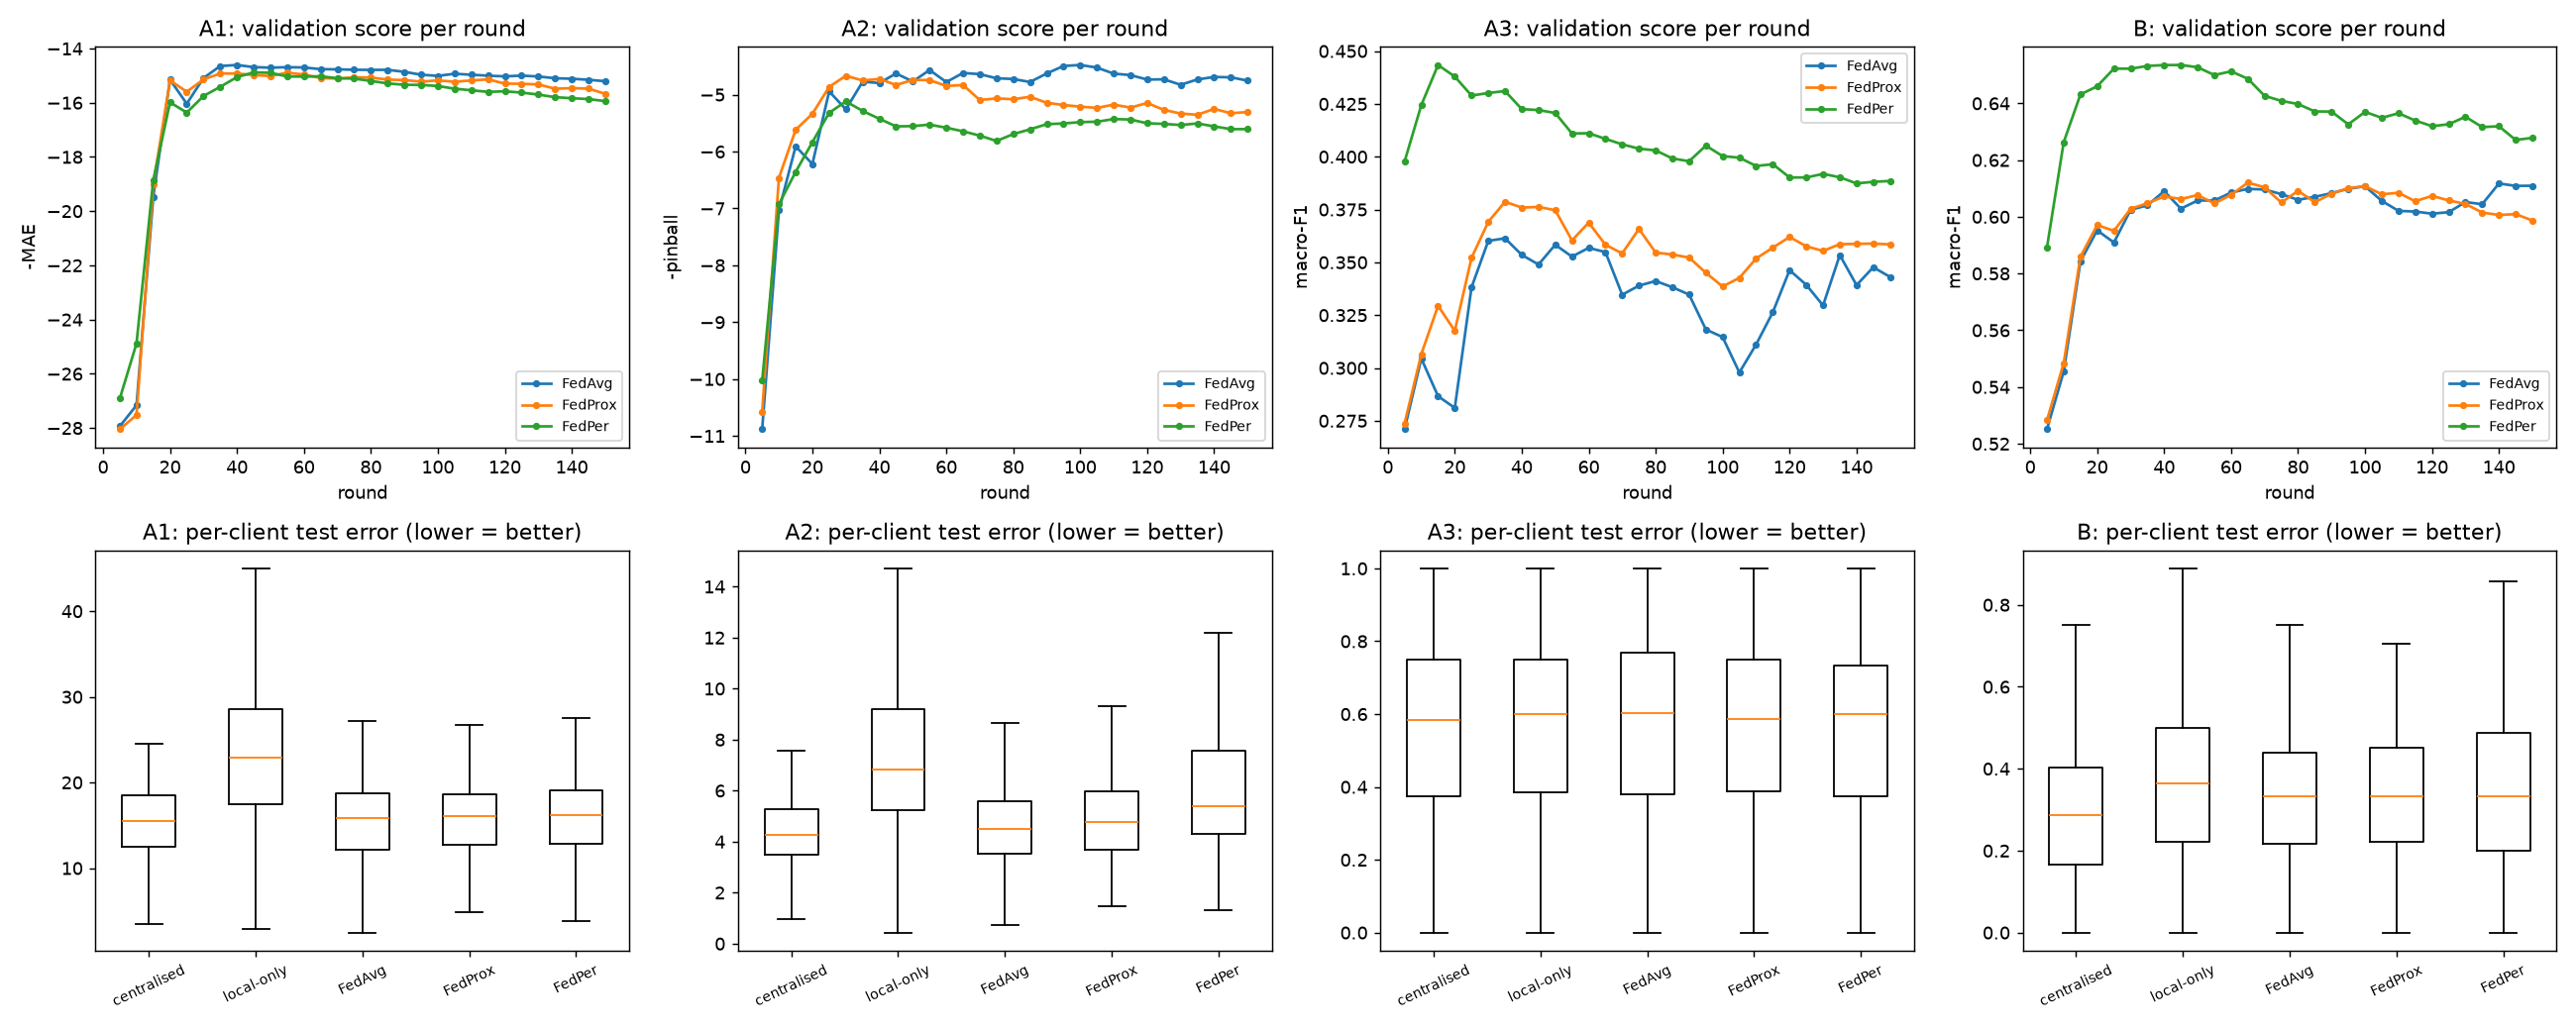

In [15]:
def make_fl_plots(R, out):
    fig, ax = plt.subplots(2, 4, figsize=(20, 8))
    for j, tk in enumerate(("A1", "A2", "A3", "B")):
        a = ax[0, j]
        for m, h in R[tk]["hist"].items():
            a.plot([r for r, _ in h], [s for _, s in h], marker="o", ms=3, label=LABEL[m])
        a.set_title(f"{tk}: validation score per round"); a.set_xlabel("round"); a.legend(fontsize=8)
        a.set_ylabel({"reg": "-MAE", "quant": "-pinball", "cls": "macro-F1"}[R[tk]["spec"]["kind"]])
        b = ax[1, j]
        names = [LABEL[m] for m in ("central", "local", "fedavg", "fedprox", "fedper") if LABEL[m] in R[tk]["cerr"]]
        b.boxplot([R[tk]["cerr"][n] for n in names], showfliers=False)
        b.set_xticklabels([n.replace("MLP ", "") for n in names], rotation=25, fontsize=8)
        b.set_title(f"{tk}: per-client test error (lower = better)")
    plt.tight_layout(); plt.savefig(f"{out}/module2_fl_evaluation.png", dpi=130); plt.close()


make_fl_plots(R, OUT_DIR)
Image(f"{OUT_DIR}/module2_fl_evaluation.png")

## 12. Cold start – users the federation has never seen
A random 20 % of users are held out entirely: they take no part in scaling, training or checkpoint selection. Their test-period sessions are then predicted by the global model (FedAvg), by the average head of FedPer, by the centralised MLP, and by the centralised HGB. Local-only models do not exist for these users. Note that these users still bring their own session *history features*; what is new is that no weights were ever trained on them.

In [16]:
def run_cold_start(tkey, frames, cfg=CFG, methods=("central", "fedavg", "fedper")):
    spec = dict(TASKS[tkey]); feats = FEATS[spec["data"]]
    users = sorted(frames); perm = np.random.default_rng(RNG).permutation(len(users))
    k = max(1, int(round(cfg.cold_frac * len(users))))
    hold = [users[i] for i in sorted(perm[:k])]; hs = set(hold)
    seen = [u for u in users if u not in hs]
    scaler = FedScaler(feats, LOCATIONS).fit([frames[u]["tr"] for u in seen])
    clients = make_clients(frames, scaler, spec, users)
    train_cl = {u: clients[u] for u in seen}
    spec["cw"] = class_weights(train_cl, spec) if spec["kind"] == "cls" else None
    sizes = [scaler.dim, *cfg.hidden, spec["n_classes"] if spec["kind"] == "cls" else 1]
    tr, te = pool_frames(frames, seen, "tr"), pool_frames(frames, hold, "te")
    attach_anchor(tkey, spec, clients, scaler, tr)
    metrics = {}
    for name, p in baselines(tkey, spec, tr, te).items():
        metrics["baseline: " + name] = task_metrics(tkey, spec, te, p)
    metrics["HGB centralised (ref.)"] = task_metrics(tkey, spec, te, hgb_predict(spec, tr, te, feats))
    for meth in methods:
        if meth == "central":
            pr = train_central(train_cl, spec, sizes, cfg, cfg.seed)
        else:
            pr, _ = train_federated(train_cl, spec, sizes, meth, cfg, cfg.seed)
        _, p, _ = eval_pool(clients, spec, pr, "te", hold)
        metrics[LABEL[meth]] = task_metrics(tkey, spec, te, p)
    return dict(summary=summary_table(metrics, tkey), metrics=metrics, n_hold=len(hold), n_seen=len(seen), n_test=len(te))


COLD = {}
if RUN_COLD_START:
    for tk in ("A1", "A2", "A3", "B"):
        COLD[tk] = run_cold_start(tk, FRAMES[TASKS[tk]["data"]])
        print(f"{tk}: held-out users={COLD[tk]['n_hold']}  federation users={COLD[tk]['n_seen']}  test rows={COLD[tk]['n_test']}")
        display(COLD[tk]["summary"])

A1: held-out users=38  federation users=150  test rows=905


,MAE,RMSE,R2
baseline: user historical mean,14.664,18.389,0.254
baseline: last session,18.805,24.750,-0.351
baseline: global mean,18.133,21.296,-0.000
HGB centralised (ref.),14.177,17.728,0.307
MLP centralised,14.676,18.829,0.218
FedAvg,14.786,18.481,0.247
FedPer,16.928,20.622,0.062


A2: held-out users=38  federation users=150  test rows=905


,pinball_loss,demand_coverage_rate,trip_safe_rate_with_reserve,mean_recommended_target_pct,mean_target_error_vs_ideal_MAE
baseline: user history q90,4.574,0.856,0.938,70.725,23.614
HGB centralised (ref.),4.135,0.853,0.939,67.715,20.622
MLP centralised,4.356,0.860,0.943,68.928,21.868
FedAvg,4.745,0.801,0.905,65.501,20.201
FedPer,12.038,0.469,0.677,50.626,20.244


A3: held-out users=38  federation users=150  test rows=905


,accuracy,macro_F1,within_one_class_accuracy
baseline: majority class,0.530,0.173,0.793
baseline: user history band,0.536,0.352,0.898
HGB centralised (ref.),0.576,0.374,0.861
MLP centralised,0.543,0.394,0.867
FedAvg,0.535,0.360,0.873
FedPer,0.530,0.201,0.807


B: held-out users=42  federation users=167  test rows=847


,accuracy,macro_F1,binary_F1
baseline: majority class,0.479,0.216,0.000
baseline: user history,0.563,0.504,0.319
HGB centralised (ref.),0.645,0.599,0.471
MLP centralised,0.639,0.607,0.520
FedAvg,0.609,0.568,0.426
FedPer,0.574,0.528,0.381


## 13. Save the federated models

Each bundle is an `.npz` (weights, plus the per-user heads for FedPer) and a `.json` (scaler statistics, task spec). `fl_predict` reloads a bundle and scores new rows with the same feature columns Module 2 produces.

In [17]:
def save_bundle(out_dir, name, pred, scaler, spec, cfg=CFG):
    arrs = {f"G{i}": p for i, p in enumerate(pred.G)}
    if pred.heads:
        for u, h in pred.heads.items():
            for i, a in enumerate(h):
                arrs[f"H__{u}__{i}"] = a
    np.savez(f"{out_dir}/{name}.npz", **arrs)
    meta = dict(scaler=scaler.to_dict(), n_pers=pred.n_pers, hidden=list(cfg.hidden),
                spec={k: (v.tolist() if isinstance(v, np.ndarray) else v) for k, v in spec.items()})
    json.dump(meta, open(f"{out_dir}/{name}.json", "w"), indent=1)


def load_bundle(out_dir, name):
    z = np.load(f"{out_dir}/{name}.npz"); meta = json.load(open(f"{out_dir}/{name}.json"))
    G = [z[f"G{i}"] for i in range(sum(k.startswith("G") for k in z.files))]
    heads = {}
    for k in z.files:
        if k.startswith("H__"):
            _, u, i = k.split("__"); heads.setdefault(u, {})[int(i)] = z[k]
    heads = {u: [h[i] for i in sorted(h)] for u, h in heads.items()} or None
    spec = meta["spec"]
    spec["cw"] = np.array(spec["cw"]) if spec.get("cw") is not None else None
    return (Predictor(G=G, heads=heads, n_pers=meta["n_pers"], anchor=spec.get("anchor")),
            FedScaler.from_dict(meta["scaler"]), spec)


def fl_predict(pred, scaler, spec, frame, uid):
    """Predict for rows of one user (frame needs the Module 2 feature columns + 'location')."""
    return to_pred(spec, pred.out(uid, scaler.transform(frame)))


# Deployed federated model per task: the method with the best VALIDATION score (test never used)
DEPLOY = {}
for tk in ("A1", "A2", "A3", "B"):
    best_val = {m: max(s for _, s in R[tk]["hist"][m]) for m in ("fedavg", "fedprox", "fedper")}
    DEPLOY[tk] = max(best_val, key=best_val.get)
    print(f"{tk}: best validation score per method {dict((k, round(v, 4)) for k, v in best_val.items())}"
          f" -> deployed: {LABEL[DEPLOY[tk]]}")

for tk in ("A1", "A2", "A3", "B"):
    for meth in ("fedavg", "fedprox", "fedper"):
        save_bundle(OUT_DIR, f"model{tk}_{meth}", R[tk]["preds"][meth], R[tk]["scaler"], R[tk]["spec"])
print("saved:", sorted(os.listdir(OUT_DIR)))

A1: best validation score per method {'fedavg': -14.6077, 'fedprox': -14.8936, 'fedper': -14.883} -> deployed: FedAvg
A2: best validation score per method {'fedavg': -4.4781, 'fedprox': -4.6679, 'fedper': -5.1182} -> deployed: FedAvg
A3: best validation score per method {'fedavg': 0.3614, 'fedprox': 0.3787, 'fedper': 0.4434} -> deployed: FedPer
B: best validation score per method {'fedavg': 0.6118, 'fedprox': 0.6121, 'fedper': 0.6535} -> deployed: FedPer
saved: ['modelA1_fedavg.json', 'modelA1_fedavg.npz', 'modelA1_fedper.json', 'modelA1_fedper.npz', 'modelA1_fedprox.json', 'modelA1_fedprox.npz', 'modelA2_fedavg.json', 'modelA2_fedavg.npz', 'modelA2_fedper.json', 'modelA2_fedper.npz', 'modelA2_fedprox.json', 'modelA2_fedprox.npz', 'modelA3_fedavg.json', 'modelA3_fedavg.npz', 'modelA3_fedper.json', 'modelA3_fedper.npz', 'modelA3_fedprox.json', 'modelA3_fedprox.npz', 'modelB_fedavg.json', 'modelB_fedavg.npz', 'modelB_fedper.json', 'modelB_fedper.npz', 'modelB_fedprox.json', 'modelB_fedpr

## 14. Decision-layer demo with the federated models

`recommend_option` is copied unchanged from Module 2. The deployed federated Model A2 supplies the q85 demand and the deployed Model B the urgency class (each chosen on validation in Section 13); only Model C's utilisation values are still hand-set here, because Model C stays centralised.

In [18]:
def recommend_option(current_soc, battery_kwh, pred_demand_q_pct, urgency_class, candidates,
                     vehicle_max_kw=11.0, urgency_weight=(1.6, 1.0, 0.5), avg_speed_kmh=30):
    """
    candidates: list of dicts {name, distance_km, power_kw, pred_utilisation}
        pred_utilisation comes from Model C (0..1).  urgency_class: 0/1/2 from Model B.
        pred_demand_q_pct from Model A (quantile).
    Returns (ranked_options, target_soc, message)
    """
    target = float(np.clip(pred_demand_q_pct + RESERVE_PCT, 30, SOC_MAX))
    if current_soc >= target:
        return [], target, (f"Current SoC {current_soc:.0f}% already covers the predicted need "
                            f"(target {target:.0f}%). No charging required now.")
    need_kwh = (target - current_soc) / 100 * battery_kwh / CHARGE_EFF
    w_t = urgency_weight[int(urgency_class)]
    out = []
    for c in candidates:
        kw = min(c["power_kw"], vehicle_max_kw)
        charge_min = need_kwh / kw * 60
        util = min(c["pred_utilisation"], 0.95)
        wait_min = (charge_min * util / (1 - util)) * 0.5                  # M/M/1-style expected queue delay
        travel_min = c["distance_km"] / avg_speed_kmh * 60
        c_rate = kw / battery_kwh
        stress_pen = (c_rate ** 1.5) * 25 * (1.0 if urgency_class == 2 else 0.4 if urgency_class == 1 else 0.0)
        score = w_t * (travel_min + wait_min + charge_min) + stress_pen
        out.append(dict(name=c["name"], travel_min=round(travel_min, 1), wait_min=round(wait_min, 1),
                        charge_min=round(charge_min, 1), total_min=round(travel_min + wait_min + charge_min, 1),
                        stress_penalty=round(stress_pen, 1), score=round(score, 1)))
    out.sort(key=lambda r: r["score"])
    msg = (f"Charge to {target:.0f}% ({need_kwh:.1f} kWh) at {out[0]['name']} "
           f"[{URG_NAMES[int(urgency_class)]} user].")
    return out, target, msg


# reload the saved bundles (as a device would) and score one held-out session
predA, scA, spA = load_bundle(OUT_DIR, f"modelA2_{DEPLOY['A2']}")
predB, scB, spB = load_bundle(OUT_DIR, f"modelB_{DEPLOY['B']}")
teA = pool_frames(FRAMES["A"], R["A2"]["uids"], "te")
qp = np.concatenate([fl_predict(predA, scA, spA, FRAMES["A"][u]["te"], u) for u in R["A2"]["uids"]])
i = int(np.argmin(np.abs(qp - 40)))
row = teA.iloc[[i]]; uid = row.user_id.iloc[0]; dem = float(qp[i])
rowB = df[(df.user_id == uid) & (df.pt == row.pt.iloc[0])]
urg = int(fl_predict(predB, scB, spB, rowB, uid)[0]) if uid in FRAMES["B"] and len(rowB) else 1
ranked, tgt, msg = recommend_option(
    current_soc=30, battery_kwh=float(row.battery_capacity.iloc[0]), pred_demand_q_pct=dem, urgency_class=urg,
    candidates=[dict(name="Station 1 (nearer, busy, 7 kW)", distance_km=1.0, power_kw=7, pred_utilisation=0.75),
                dict(name="Station 2 (farther, free, 22 kW)", distance_km=3.5, power_kw=22, pred_utilisation=0.15)])
print(f"user {uid}: predicted q85 demand = {dem:.1f}% | urgency = {URG_NAMES[urg]}")
print(msg)
pd.DataFrame(ranked)

user OSL_S_KT63: predicted q85 demand = 40.0% | urgency = Moderate
Charge to 55% (13.4 kWh) at Station 2 (farther, free, 22 kW) [Moderate user].


,name,travel_min,wait_min,charge_min,total_min,stress_penalty,score
0,"Station 2 (farther, free, 22 kW)",7.0,6.4,73.1,86.5,1.1,87.7
1,"Station 1 (nearer, busy, 7 kW)",2.0,172.3,114.9,289.2,0.6,289.7


## 15. Communication cost and metrics export

In [19]:
cost = pd.DataFrame({tk: dict(clients=R[tk]["n_clients"], params=R[tk]["n_params"],
                              MB_per_client_per_round_up_and_down=round(2 * R[tk]["n_params"] * 8 / 1e6, 3),
                              MB_per_client_full_training=round(2 * R[tk]["n_params"] * 8 * CFG.rounds / 1e6, 2))
                     for tk in R}).T
print(cost)

export = dict(config={k: (list(v) if isinstance(v, tuple) else v) for k, v in vars(CFG).items()},
              test_metrics={tk: R[tk]["metrics"] for tk in R},
              cold_start={tk: COLD[tk]["metrics"] for tk in COLD},
              n_clients={tk: R[tk]["n_clients"] for tk in R})
json.dump(export, open(f"{OUT_DIR}/module2_fl_metrics.json", "w"), indent=2,
          default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("saved metrics + models to", OUT_DIR)

    clients  params  MB_per_client_per_round_up_and_down  \
A1    188.0  6529.0                                0.104   
A2    188.0  6529.0                                0.104   
A3    188.0  6628.0                                0.106   
B     209.0  5059.0                                0.081   

    MB_per_client_full_training  
A1                        15.67  
A2                        15.67  
A3                        15.91  
B                         12.14  
saved metrics + models to ./module2_fl_outputs


## 16. Explainability layer (SHAP)

Everything above is **already trained**; this section trains nothing. It opens the trained federated models (`R[...]["preds"]`) and explains their predictions with **SHAP**, so that every recommendation can be traced back to the features that caused it.

| Question | Where answered |
|---|---|
| Which features drive each model overall? | 16.3 – global importance, 16.5 – direction (beeswarm) and dependence plots |
| Which *kinds* of information matter (time, vehicle, recent sessions, long-run habits)? | 16.4 – feature families |
| Why did the app recommend *this* charge level for *this* session? | 16.6 – local explanation, tied to the Section 14 decision demo |
| Can this be done without pooling user data? | 16.7 – federated SHAP (each client explains itself, the server only averages) |

**Design choices**
- **Model-agnostic Kernel SHAP.** The federated models are NumPy MLPs, so the framework-specific explainers (Tree/Deep/Gradient) do not apply. `shap.KernelExplainer` only needs a `predict` function.
- **Players = original features.** A feature's value, its "was missing" flag, and (for `location`) the 12 one-hot site columns are switched on/off *together*, so Shapley values are reported per real feature (≈ 35 players for Model A, ≈ 23 for Model B) rather than for 68 / 44 scaled columns.
- **What is explained.** A1 and A2: the prediction in **SoC percentage points** (A2 = the q85 demand that becomes `target = q85 + 15 %`). A3 and B: the **class probability** (focus class: A3 = *Near-full*, B = *Time-critical*).
- **Which model.** The deployed federated model of each task (`DEPLOY`, chosen on validation in Section 13), the same models the Section 14 decision demo uses. For FedPer models each user's explanation uses *their own* personalised head. For A1 and A2 the explained output includes the user's own mean need that the network is anchored to, so its credit goes to the history features.
- **Reference ("baseline").** A random sample of training rows. SHAP values answer: *"how far did this feature move the prediction away from the average prediction on that reference?"*

> **Run order:** run the notebook top to bottom first (or at least Sections 0–14) so that `R`, `FRAMES`, `LOCATIONS` and the Section 14 demo variables (`row`, `uid`, `rowB`) exist. Nothing is retrained. Full SHAP run: a few minutes on one CPU; `QUICK = True` shrinks it automatically.

In [20]:
# --- 16.1 setup -----------------------------------------------------------------
import subprocess, sys
try:
    import shap
except ImportError:                                   # one-off install
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "shap"])
    import shap
from matplotlib.patches import Patch
print("shap", shap.__version__)

SHAP_CFG = SimpleNamespace(
    method=None,             # None = the deployed model of each task (DEPLOY); or "fedavg" | "fedprox" | "fedper" | "central"
    n_background=40,         # reference rows (pooled view)
    nsamples=500,            # Kernel SHAP coalition samples per explained row
    rows_per_client=3,       # test rows explained per client (pooled view)
    fed_rows_per_client=15,  # test rows explained per client (federated view)
    fed_n_background=20,     # each client's own reference rows (federated view)
    fed_nsamples=300,
    max_clients=None,        # None = all clients
    top_k=12,                # features shown in plots
    seed=RNG)
if QUICK:
    SHAP_CFG.n_background, SHAP_CFG.nsamples, SHAP_CFG.rows_per_client = 10, 100, 1
    SHAP_CFG.fed_rows_per_client, SHAP_CFG.fed_n_background, SHAP_CFG.fed_nsamples = 3, 8, 100
    SHAP_CFG.max_clients = 15

SHAP_TASKS = ("A1", "A2", "A3", "B")
FOCUS = {"A1": 0, "A2": 0, "A3": 3, "B": 0}          # output explained in the beeswarm / local plots
OUT_NAME = {"A1": "next-charge demand (SoC %-pts)", "A2": "q85 demand (SoC %-pts)",
            "A3": "P(Near-full band)", "B": "P(Time-critical)"}
MISSING = -9999.0                                      # NaN sentinel inside the SHAP input matrix

FRIENDLY = {
    "hour": "arrival hour", "dow": "day of week", "month": "month", "weekend": "weekend",
    "hour_sin": "arrival hour (sin)", "hour_cos": "arrival hour (cos)", "location": "charging site",
    "battery_capacity": "battery capacity", "charging_power": "charger power",
    "cur_soc_need": "SoC charged this session", "cur_energy": "energy this session",
    "cur_charge_time": "charging time this session", "n_prev": "# previous sessions",
    "hrs_since_prev_plugout": "hours since last plug-out", "hist_hour_mean": "usual arrival hour",
    "soc_lag1": "SoC need, last session", "soc_lag2": "SoC need, 2 sessions ago",
    "soc_lag3": "SoC need, 3 sessions ago", "soc_roll5": "SoC need, mean of last 5",
    "soc_hist_mean": "SoC need, history mean", "soc_hist_med": "SoC need, history median",
    "soc_hist_q75": "SoC need, history q75", "soc_hist_q90": "SoC need, history q90",
    "soc_hist_std": "SoC need, history std", "soc_hist_dow_mean": "SoC need, same weekday mean",
    "soc_per_day_hist": "SoC need per day (history)", "gap_prev_days": "days since last session",
    "gap_hist_mean": "typical gap between sessions", "gap_hist_med": "median gap between sessions",
    "after_dow_gap_mean": "gap after this weekday (history)", "after_dow_soc_mean": "next SoC need after this weekday",
    "after_dow_soc_med": "next SoC need after this weekday (median)", "after_hour_soc_mean": "next SoC need after this hour",
    "after_soc_mean": "next SoC need (overall history)", "conn_hist_mean": "dwell time, history mean",
    "conn_hist_med": "dwell time, history median", "conn_hist_dow_mean": "dwell time, same weekday",
    "conn_hist_hour_mean": "dwell time, same arrival hour", "conn_lag1": "dwell time, last session",
    "slack_lag1": "slack, last session", "slack_hist_med": "slack, history median"}
nice = lambda f: FRIENDLY.get(f, f.replace("_", " "))
shap_method = lambda tk: SHAP_CFG.method or DEPLOY[tk]

FAMILIES = {
    "Time & calendar": ["hour", "dow", "month", "weekend", "hour_sin", "hour_cos"],
    "Charging site": ["location"],
    "Vehicle & current session": ["battery_capacity", "charging_power", "cur_soc_need", "cur_energy", "cur_charge_time"],
    "Recent sessions": ["soc_lag1", "soc_lag2", "soc_lag3", "soc_roll5", "conn_lag1", "slack_lag1",
                        "hrs_since_prev_plugout", "gap_prev_days"]}
FAM_OF = {f: fam for fam, fs in FAMILIES.items() for f in fs}
family = lambda f: FAM_OF.get(f, "Long-run user habits")
FAM_ORDER = list(FAMILIES) + ["Long-run user habits"]
FAM_COLOR = dict(zip(FAM_ORDER, plt.cm.tab10.colors))
UNITS = lambda tk: 100.0 if TASKS[tk]["kind"] == "cls" else 1.0      # probabilities shown as %-points
UNIT_LABEL = lambda tk: "pp of probability" if TASKS[tk]["kind"] == "cls" else "SoC %-pts"


# --- model wrapper: raw feature matrix -> model output ---------------------------
def shap_players(scaler):
    """One SHAP player per original feature (value + missing flag together); sites = one player."""
    return list(scaler.feats) + ["location"]


def raw_matrix(frame, scaler):
    """Original-unit feature matrix (n x players). NaN -> MISSING sentinel, location -> site index."""
    X = frame[scaler.feats].to_numpy(float).copy()
    X[~np.isfinite(X)] = MISSING
    loc = pd.Categorical(frame["location"], categories=scaler.locations).codes.astype(float)[:, None]
    return np.hstack([X, loc])


def scale_matrix(M, scaler):
    """Same arithmetic as FedScaler.transform, but from the raw matrix (so SHAP can mask players)."""
    F = len(scaler.feats)
    X = M[:, :F].copy(); X[X <= MISSING / 2] = np.nan
    ok = np.isfinite(X)
    Z = np.clip(np.where(ok, (X - scaler.mean) / scaler.std, 0.0), -scaler.clip, scaler.clip)
    miss = (~ok[:, scaler.miss_idx]).astype(float)
    loc = (np.rint(M[:, F]).astype(int)[:, None] == np.arange(len(scaler.locations))[None, :]).astype(float)
    return np.hstack([Z, miss, loc])


def model_fn(pred, spec, scaler, uid):
    """f(M) -> (n,) in SoC %-pts for A1/A2, (n, classes) probabilities for A3/B. Unclipped, so SHAP is exact."""
    def f(M):
        out = pred.out(uid, scale_matrix(np.asarray(M, float), scaler))
        if spec["kind"] == "cls":
            z = out - out.max(1, keepdims=True); p = np.exp(z)
            return p / p.sum(1, keepdims=True)
        return out[:, 0] * spec["scale"]
    return f


def _as_nPC(sv):
    """shap returns a list (old) or an (n, P, C) array (new) -> always (n, P, C)."""
    if isinstance(sv, list):
        sv = np.stack(sv, axis=-1)
    sv = np.asarray(sv)
    return sv[:, :, None] if sv.ndim == 2 else sv


# --- Kernel SHAP over the federation ----------------------------------------------
def shap_run(R, tkey, method, bg="pooled", rows_per_client=3, n_bg=40, nsamples=500,
             max_clients=None, seed=RNG):
    """Explain test rows client by client, each with that client's own model (own head for FedPer).
    bg='pooled': common reference sample of training rows (development view, population baseline).
    bg='local' : each client uses only its own training rows (nothing leaves the device)."""
    Rk = R[tkey]; spec, scaler, pred = Rk["spec"], Rk["scaler"], Rk["preds"][method]
    frames = FRAMES[TASKS[tkey]["data"]]; rng = np.random.default_rng(seed)
    uids = list(Rk["uids"])
    if max_clients is not None and max_clients < len(uids):
        uids = [uids[i] for i in sorted(rng.choice(len(uids), max_clients, replace=False))]
    B_pool = None
    if bg == "pooled":
        pool = np.vstack([raw_matrix(frames[u]["tr"], scaler) for u in Rk["uids"]])
        B_pool = pool[rng.choice(len(pool), min(n_bg, len(pool)), replace=False)]
    rec = {k: [] for k in ("uid", "raw", "phi", "base", "fx")}
    for u in uids:
        te = frames[u]["te"]
        if len(te) == 0:
            continue
        Xte = raw_matrix(te.iloc[rng.choice(len(te), min(rows_per_client, len(te)), replace=False)], scaler)
        if bg == "local":
            tr = raw_matrix(frames[u]["tr"], scaler)
            B = tr[rng.choice(len(tr), min(n_bg, len(tr)), replace=False)]
        else:
            B = B_pool
        f = model_fn(pred, spec, scaler, u)
        ex = shap.KernelExplainer(f, B)
        phi = _as_nPC(ex.shap_values(Xte, nsamples=nsamples, l1_reg=False, silent=True))
        n = len(Xte); C = phi.shape[2]
        rec["uid"] += [u] * n; rec["raw"].append(Xte); rec["phi"].append(phi)
        rec["base"].append(np.tile(np.atleast_1d(ex.expected_value).reshape(1, -1), (n, 1)))
        rec["fx"].append(np.asarray(f(Xte)).reshape(n, C))
    S = dict(uid=np.array(rec["uid"], dtype=object), raw=np.vstack(rec["raw"]), phi=np.concatenate(rec["phi"]),
             base=np.vstack(rec["base"]), fx=np.vstack(rec["fx"]), players=shap_players(scaler),
             bg=B_pool, method=method, bg_mode=bg, tkey=tkey)
    S["additivity_err"] = float(np.abs(S["base"] + S["phi"].sum(1) - S["fx"]).max())
    return S


def importance(S):
    """Mean |SHAP| per player (averaged over rows and, for classifiers, over classes)."""
    return pd.Series(np.abs(S["phi"]).mean(0).mean(-1), index=S["players"])


def check_wrapper(R, tkey, method):
    """The raw-matrix wrapper must reproduce the trained model's own forward pass exactly."""
    Rk = R[tkey]; u = Rk["uids"][0]; fr = FRAMES[TASKS[tkey]["data"]][u]["te"]
    spec, sc, pred = Rk["spec"], Rk["scaler"], Rk["preds"][method]
    assert np.allclose(scale_matrix(raw_matrix(fr, sc), sc), sc.transform(fr)), "scaling mismatch"
    ref = pred.out(u, sc.transform(fr)); got = model_fn(pred, spec, sc, u)(raw_matrix(fr, sc))
    if spec["kind"] == "cls":
        assert np.array_equal(got.argmax(1), ref.argmax(1)), "class mismatch"
    else:
        assert np.allclose(got, ref[:, 0] * spec["scale"]), "output mismatch"
    return True


shap 0.54.1


### 16.2 Run SHAP on the trained models
For every task, up to `rows_per_client` test sessions of each client are explained against a shared reference sample. Two safety checks are printed: the **wrapper check** (the SHAP wrapper reproduces the trained model's output exactly) and the **additivity error** (`baseline + Σ SHAP = prediction`, should be ≈ 0).

In [21]:
SH, IMP = {}, {}
for tk in SHAP_TASKS:
    assert tk in R, "run the earlier sections first (R must hold the trained models)"
    check_wrapper(R, tk, shap_method(tk))
    t0 = time.time()
    SH[tk] = shap_run(R, tk, shap_method(tk), bg="pooled", rows_per_client=SHAP_CFG.rows_per_client,
                      n_bg=SHAP_CFG.n_background, nsamples=SHAP_CFG.nsamples, max_clients=SHAP_CFG.max_clients)
    IMP[tk] = importance(SH[tk])
    print(f"{tk}: {len(SH[tk]['uid'])} sessions from {len(set(SH[tk]['uid']))} clients explained | "
          f"{len(SH[tk]['players'])} features | wrapper check OK | additivity err {SH[tk]['additivity_err']:.1e} | "
          f"{time.time() - t0:.0f}s")

A1: 564 sessions from 188 clients explained | 35 features | wrapper check OK | additivity err 2.1e-14 | 10s


A2: 564 sessions from 188 clients explained | 35 features | wrapper check OK | additivity err 2.8e-14 | 10s


A3: 564 sessions from 188 clients explained | 35 features | wrapper check OK | additivity err 3.3e-16 | 11s


B: 627 sessions from 209 clients explained | 23 features | wrapper check OK | additivity err 1.1e-16 | 10s


### 16.3 Global feature importance
Mean |SHAP| = the average amount (in the unit of the output) by which a feature moves a single prediction. Bars are coloured by feature family. For A1/A2 the unit is SoC percentage points; for A3/B it is percentage points of class probability averaged over the classes.

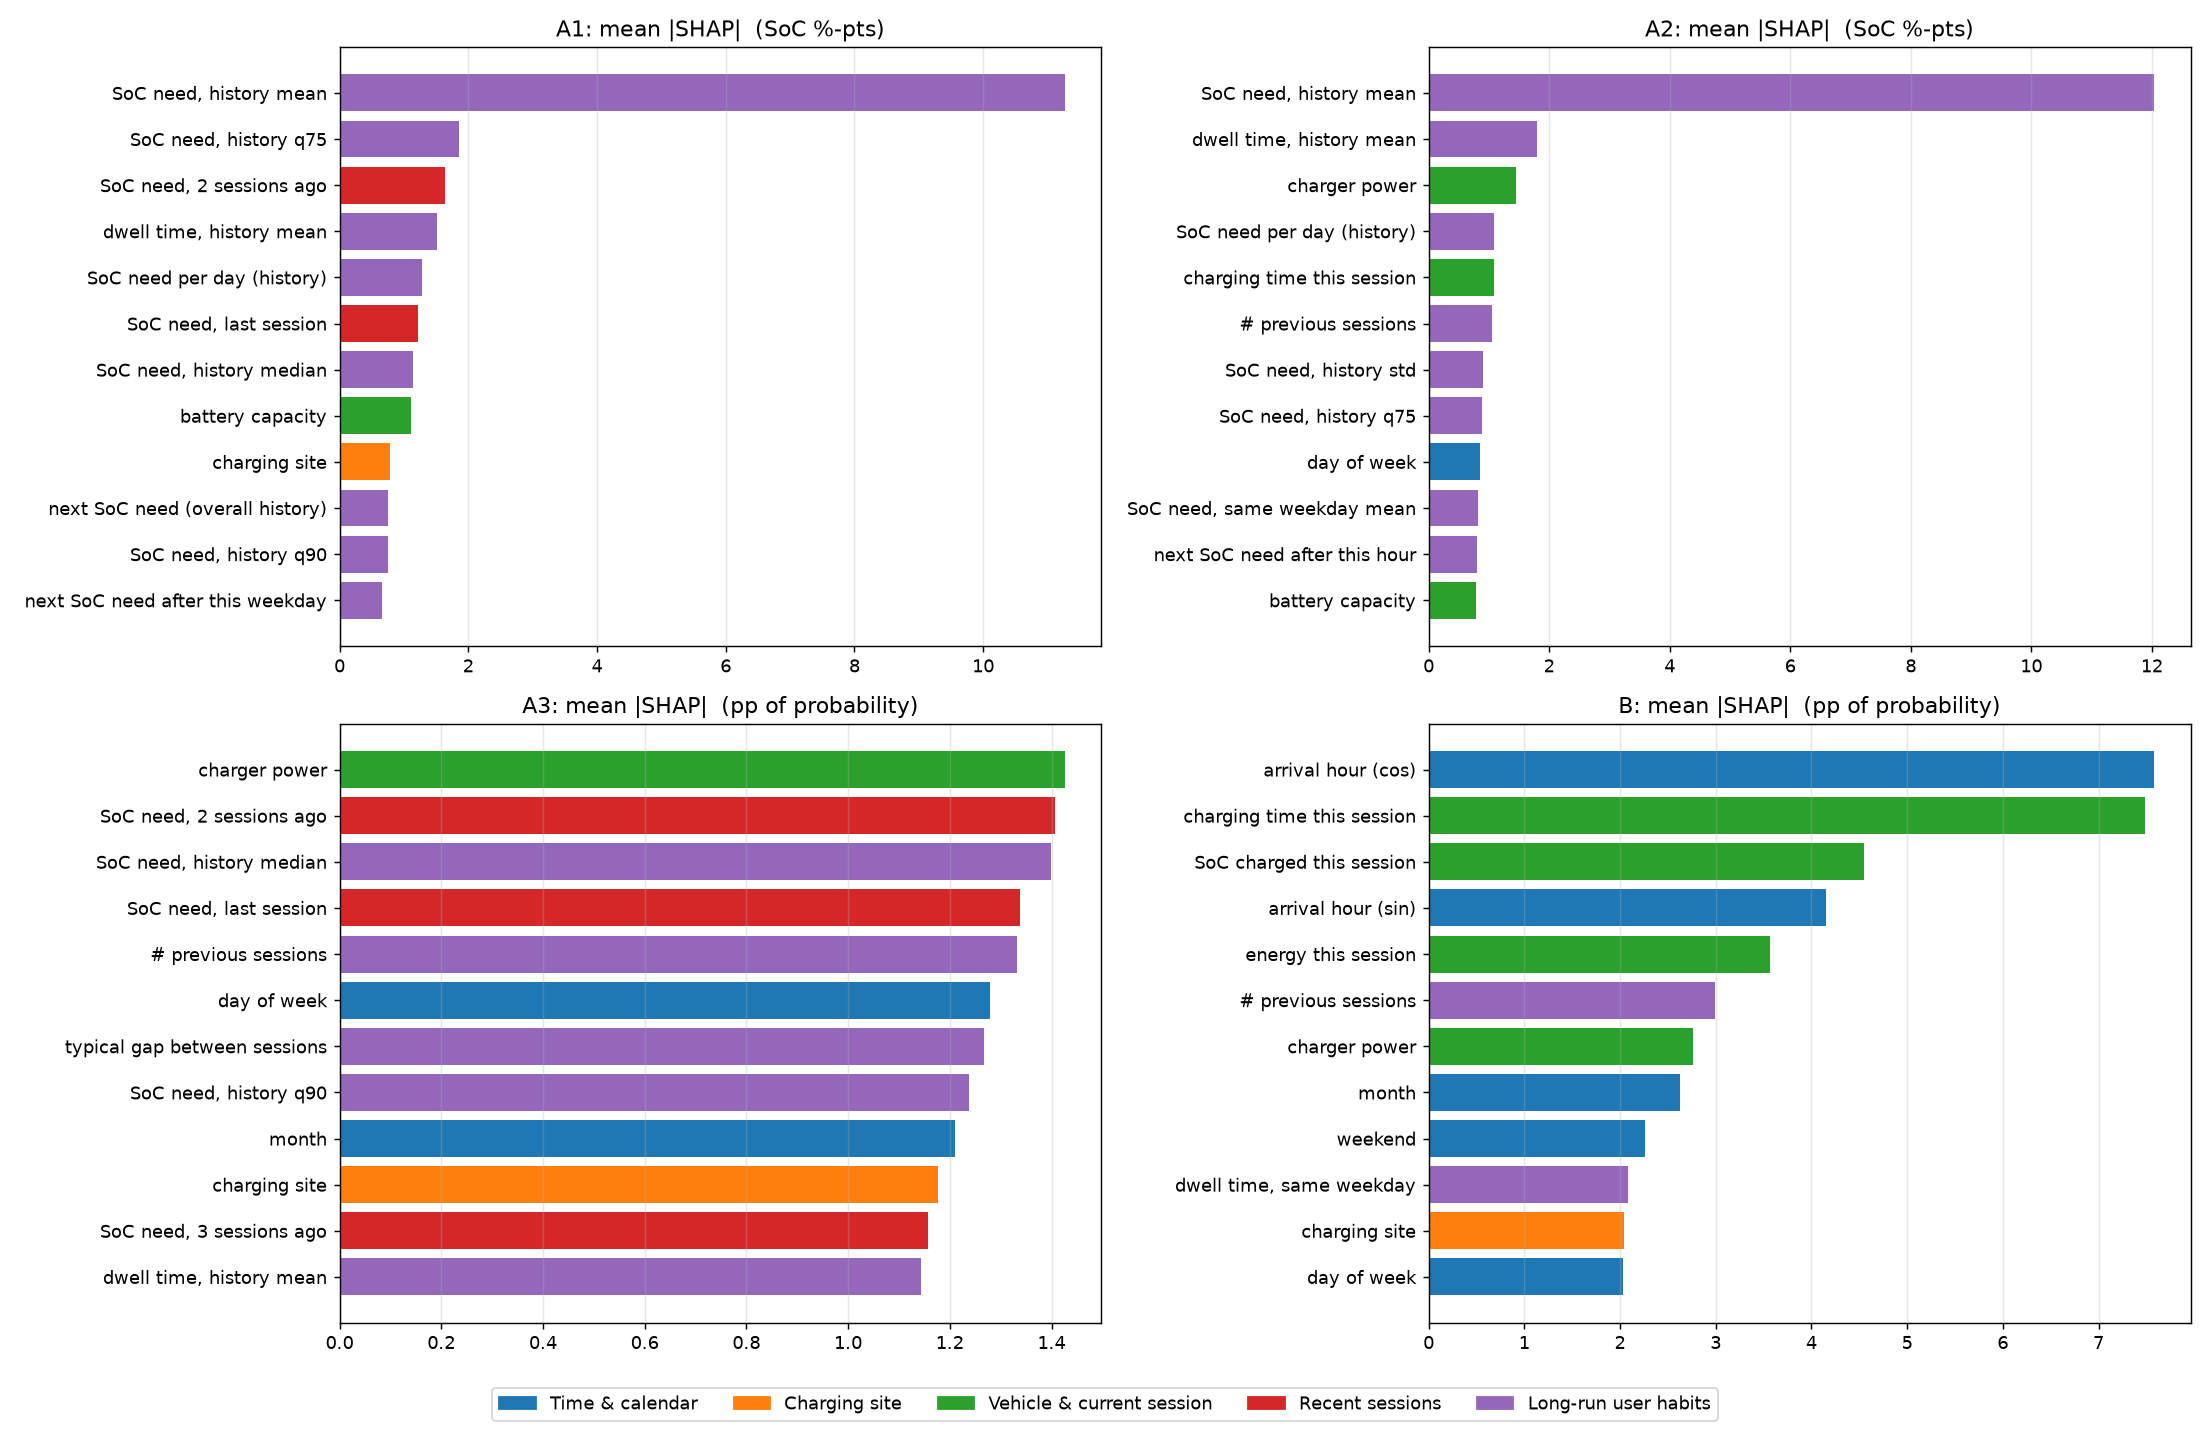

,A1,A2,A3,B
#1,"SoC need, history mean (11.27)","SoC need, history mean (12.04)",charger power (1.43),arrival hour (cos) (7.58)
#2,"SoC need, history q75 (1.85)","dwell time, history mean (1.79)","SoC need, 2 sessions ago (1.41)",charging time this session (7.48)
#3,"SoC need, 2 sessions ago (1.64)",charger power (1.44),"SoC need, history median (1.40)",SoC charged this session (4.55)
#4,"dwell time, history mean (1.52)",SoC need per day (history) (1.08),"SoC need, last session (1.34)",arrival hour (sin) (4.16)
#5,SoC need per day (history) (1.28),charging time this session (1.08),# previous sessions (1.33),energy this session (3.56)


In [22]:
def plot_importance(IMP, path):
    fig, ax = plt.subplots(2, 2, figsize=(17, 11))
    for a, tk in zip(ax.ravel(), SHAP_TASKS):
        top = (IMP[tk] * UNITS(tk)).sort_values().tail(SHAP_CFG.top_k)
        a.barh([nice(n) for n in top.index], top.values, color=[FAM_COLOR[family(n)] for n in top.index])
        a.set_title(f"{tk}: mean |SHAP|  ({UNIT_LABEL(tk)})"); a.grid(axis="x", alpha=.3)
    fig.legend(handles=[Patch(color=FAM_COLOR[f], label=f) for f in FAM_ORDER], loc="lower center", ncol=5, fontsize=10)
    plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.savefig(path, dpi=130); plt.close()


plot_importance(IMP, f"{OUT_DIR}/module2_shap_importance.png")
display(Image(f"{OUT_DIR}/module2_shap_importance.png"))

top_tbl = pd.DataFrame({tk: [f"{nice(n)} ({v * UNITS(tk):.2f})" for n, v in IMP[tk].sort_values(ascending=False).head(5).items()]
                        for tk in SHAP_TASKS}, index=[f"#{i}" for i in range(1, 6)])
top_tbl

### 16.4 Which kind of information drives each model?
Because SHAP values are additive, a family's contribution is simply the sum of its features' mean |SHAP|. The table shows each family's share (%) of the total.

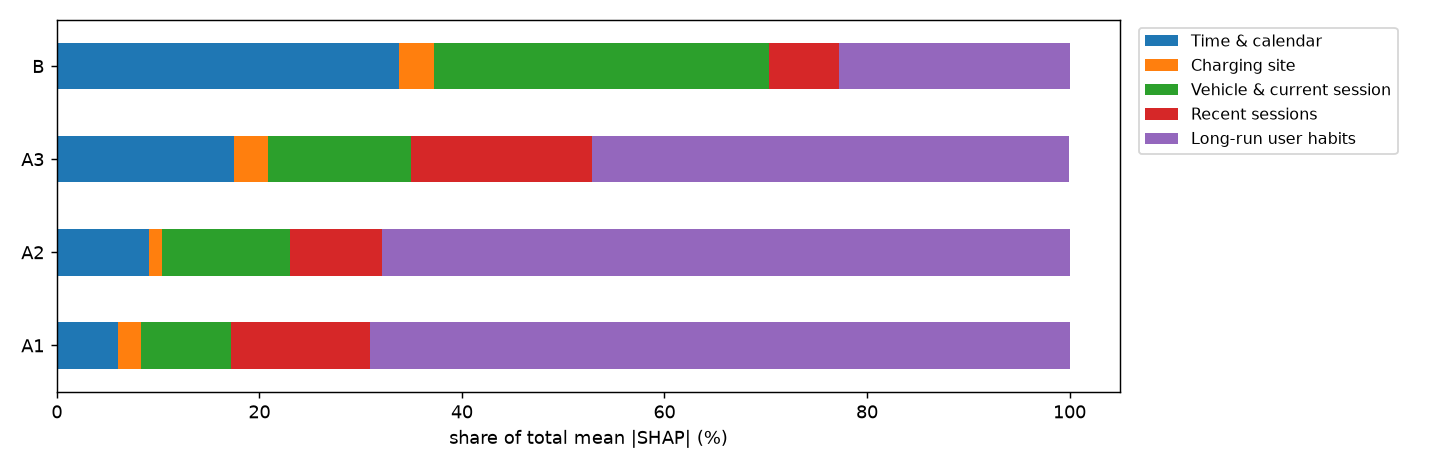

,A1,A2,A3,B
Time & calendar,6.0,9.1,17.5,33.8
Charging site,2.3,1.3,3.4,3.4
Vehicle & current session,8.9,12.6,14.1,33.1
Recent sessions,13.7,9.1,17.8,6.9
Long-run user habits,69.1,67.9,47.1,22.8


In [23]:
FAM = pd.DataFrame({tk: IMP[tk].groupby(family).sum().reindex(FAM_ORDER).fillna(0) for tk in SHAP_TASKS})
FAM_PCT = (FAM / FAM.sum() * 100).round(1)

ax = FAM_PCT.T.plot(kind="barh", stacked=True, figsize=(11, 3.6), color=[FAM_COLOR[f] for f in FAM_ORDER])
ax.set_xlabel("share of total mean |SHAP| (%)"); ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=9)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/module2_shap_families.png", dpi=130); plt.close()
display(Image(f"{OUT_DIR}/module2_shap_families.png"))
FAM_PCT

### 16.5 Direction of the effect – beeswarm and dependence plots
**Beeswarm:** one dot = one session. Horizontal position = how much the feature pushed that prediction up (right) or down (left); colour = the feature's value (red high, blue low, grey missing/not meaningful as a number). `charging site` is categorical, so it is drawn grey. Output shown: A1/A2 SoC %-pts, A3 *Near-full* probability, B *Time-critical* probability.

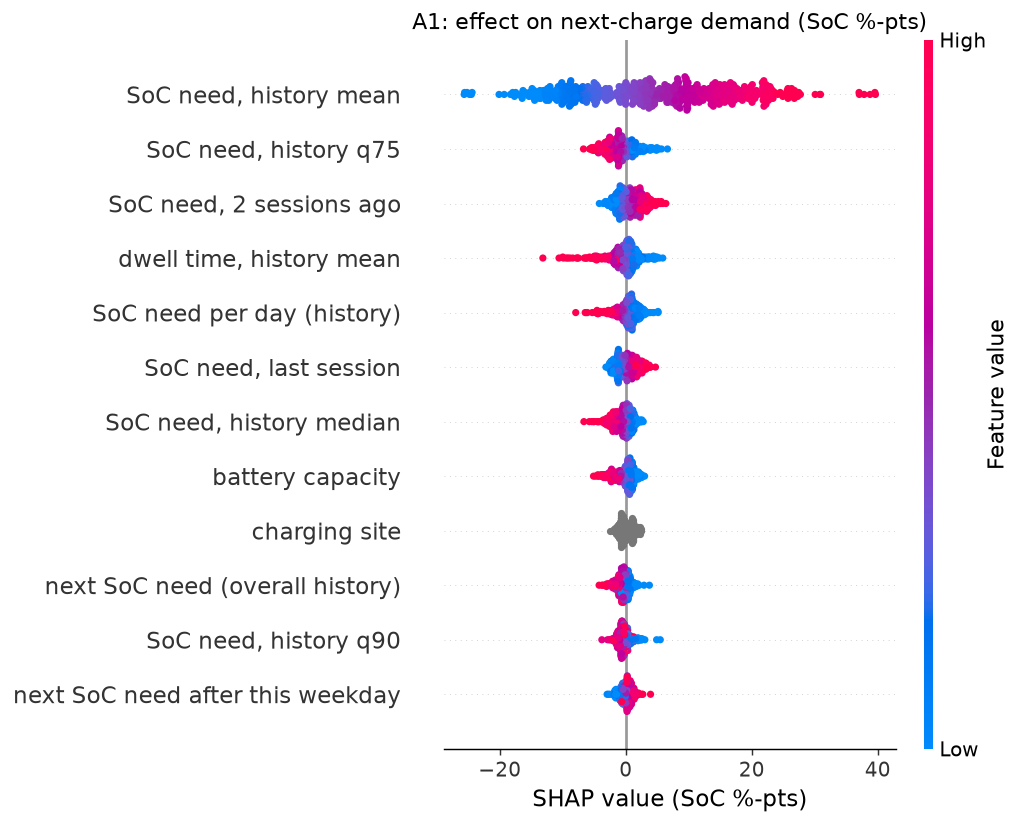

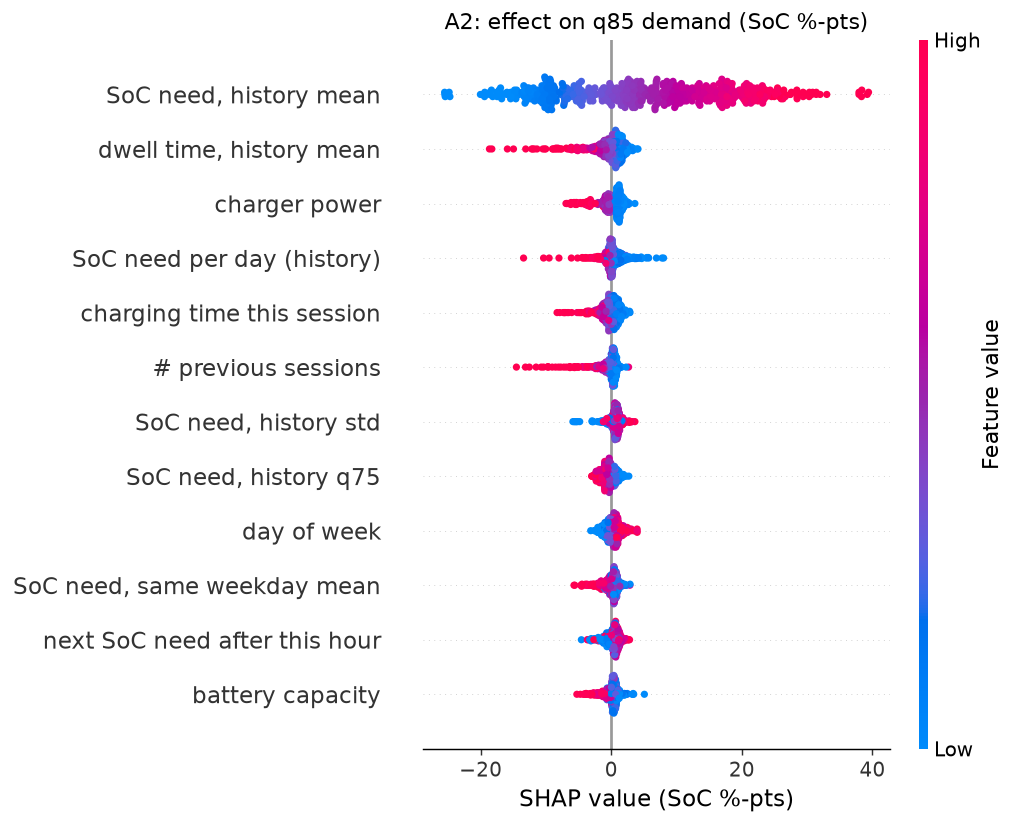

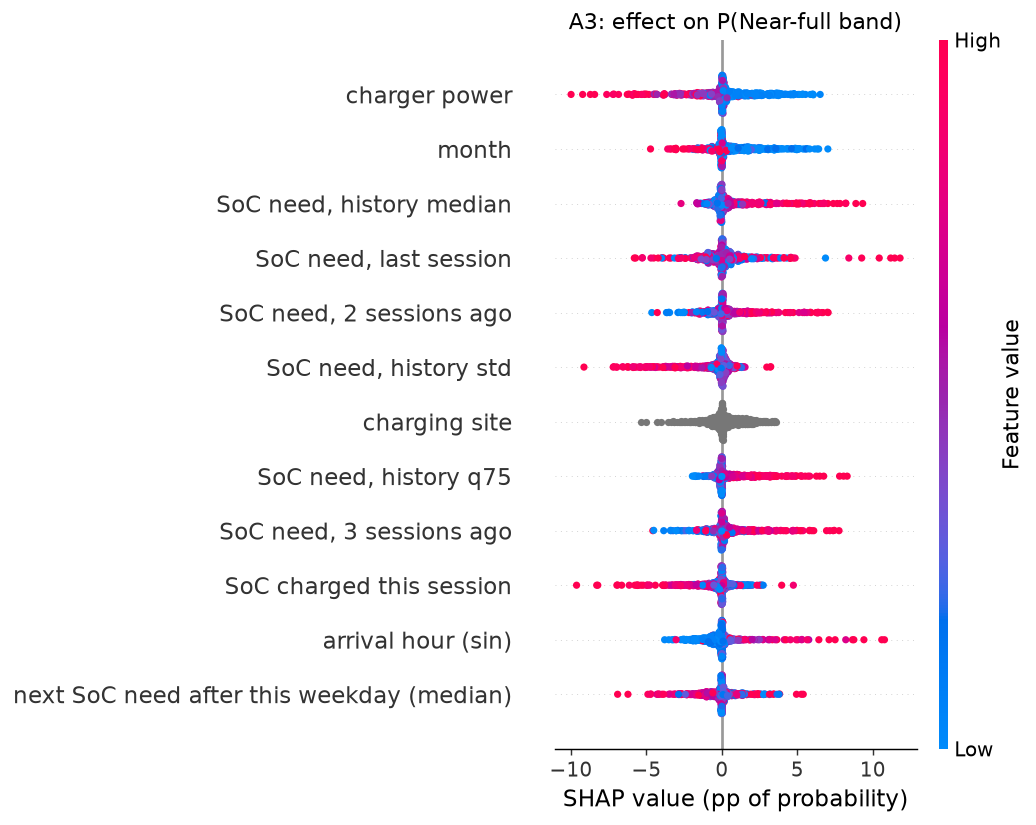

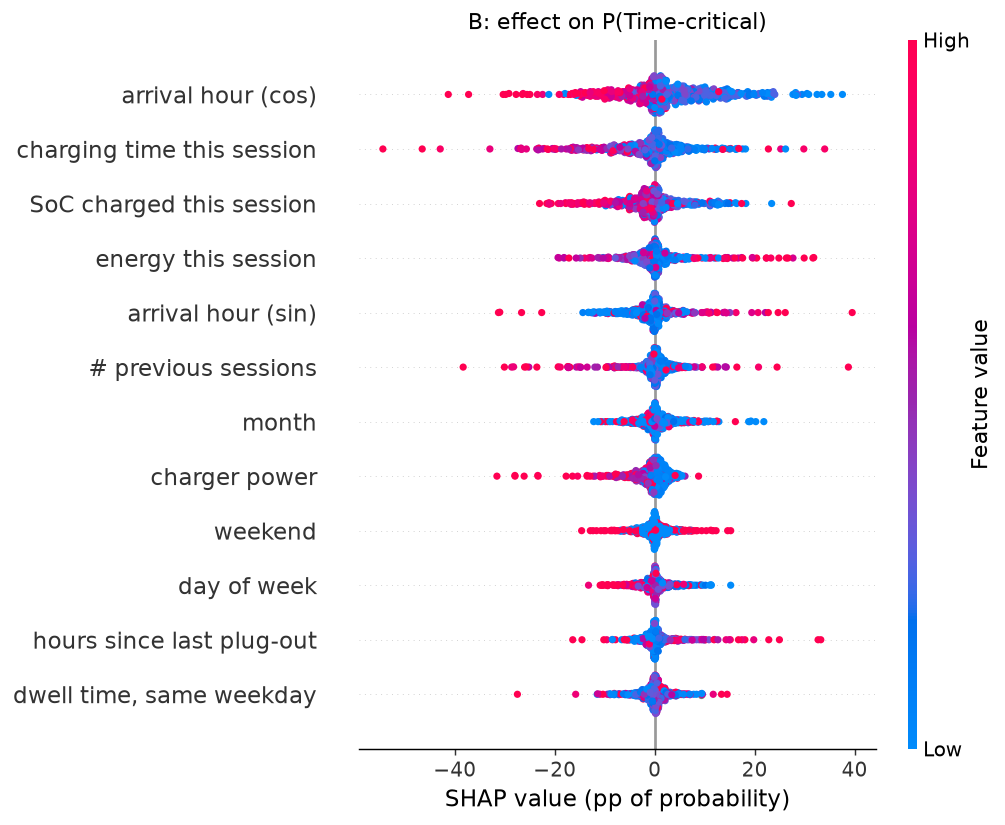

In [24]:
def display_matrix(S):
    D = S["raw"].copy(); D[D <= MISSING / 2] = np.nan
    D[:, S["players"].index("location")] = np.nan          # categorical: no colour scale
    return D


def plot_beeswarm(S, tk, path):
    c = FOCUS[tk]
    plt.figure(figsize=(9.5, 6.5))
    shap.summary_plot(S["phi"][:, :, c] * UNITS(tk), display_matrix(S), feature_names=[nice(p) for p in S["players"]],
                      max_display=SHAP_CFG.top_k, show=False)
    plt.title(f"{tk}: effect on {OUT_NAME[tk]}"); plt.xlabel(f"SHAP value ({UNIT_LABEL(tk)})")
    plt.savefig(path, dpi=130, bbox_inches="tight"); plt.close()


for tk in SHAP_TASKS:
    plot_beeswarm(SH[tk], tk, f"{OUT_DIR}/module2_shap_beeswarm_{tk}.png")
    display(Image(f"{OUT_DIR}/module2_shap_beeswarm_{tk}.png"))

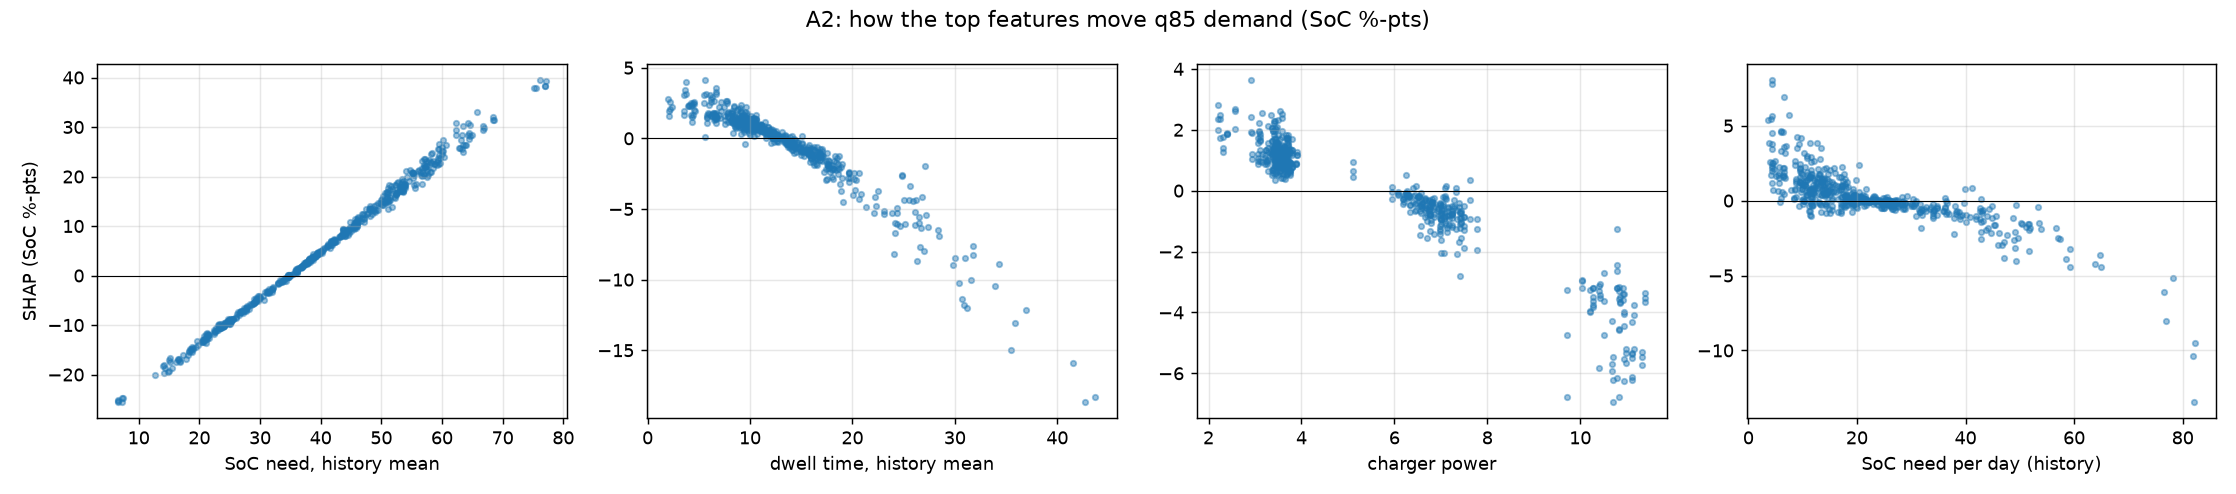

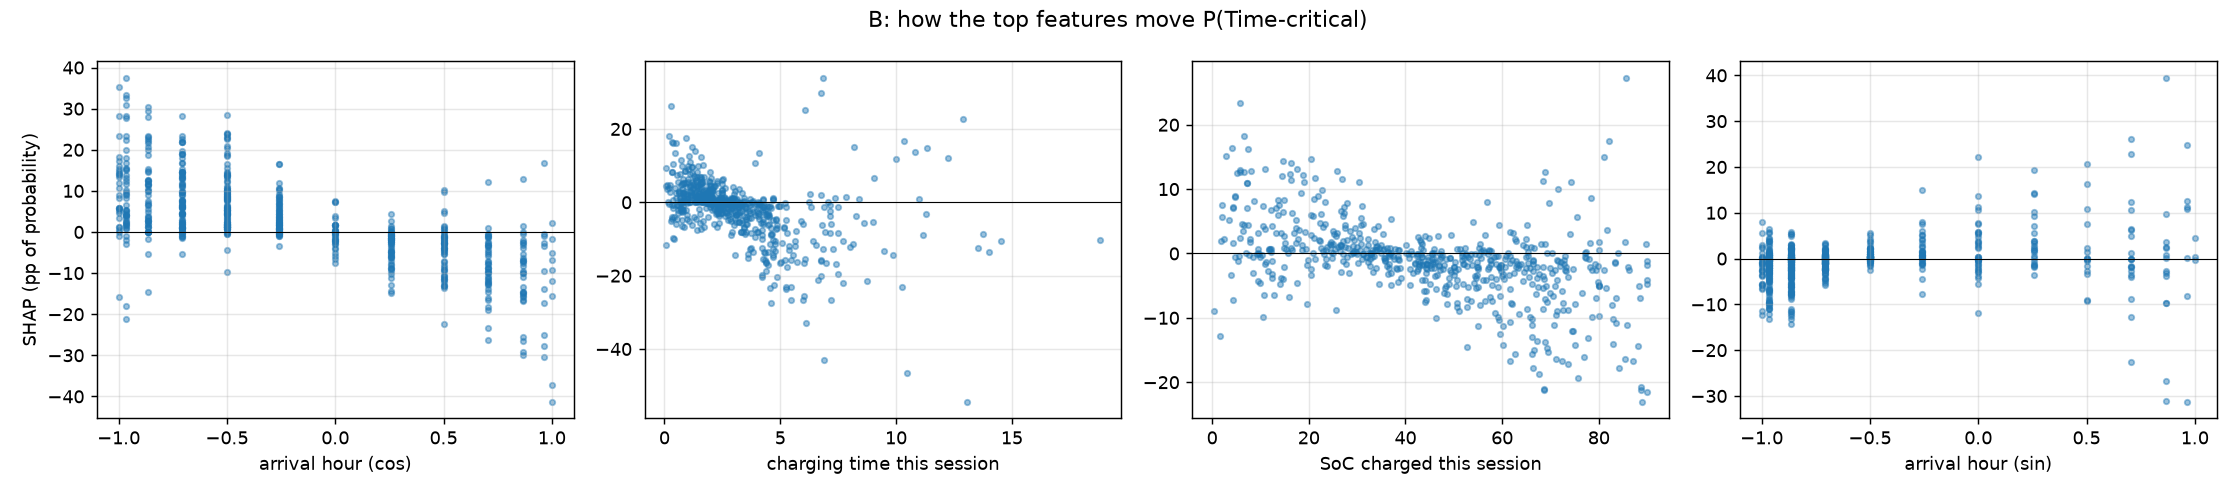

In [25]:
def plot_dependence(S, tk, k=4, path=None):
    """Raw feature value (x) vs its SHAP value (y) for the k most important numeric features."""
    c = FOCUS[tk]; imp = importance(S)
    feats = [f for f in imp.sort_values(ascending=False).index if f != "location"][:k]
    D = display_matrix(S)
    fig, ax = plt.subplots(1, k, figsize=(4.3 * k, 3.8))
    for a, f in zip(np.atleast_1d(ax), feats):
        j = S["players"].index(f)
        a.scatter(D[:, j], S["phi"][:, j, c] * UNITS(tk), s=9, alpha=.45)
        a.axhline(0, color="k", lw=.6); a.set_xlabel(nice(f)); a.grid(alpha=.3)
    np.atleast_1d(ax)[0].set_ylabel(f"SHAP ({UNIT_LABEL(tk)})")
    fig.suptitle(f"{tk}: how the top features move {OUT_NAME[tk]}")
    plt.tight_layout(); plt.savefig(path, dpi=130); plt.close()


for tk in ("A2", "B"):
    plot_dependence(SH[tk], tk, path=f"{OUT_DIR}/module2_shap_dependence_{tk}.png")
    display(Image(f"{OUT_DIR}/module2_shap_dependence_{tk}.png"))

### 16.6 Local explanation – *why this recommendation?*
This reuses the **same session** as the Section 14 decision demo (`row`, `uid`, `rowB`). The explanation of Model A2 is directly the explanation of the **target charge level**, because `target = q85 demand + 15 % reserve` and the reserve is a constant. The explanation of Model B tells why the user is treated as Time-critical / Moderate / Flexible, which sets the weight on time in the ranking.

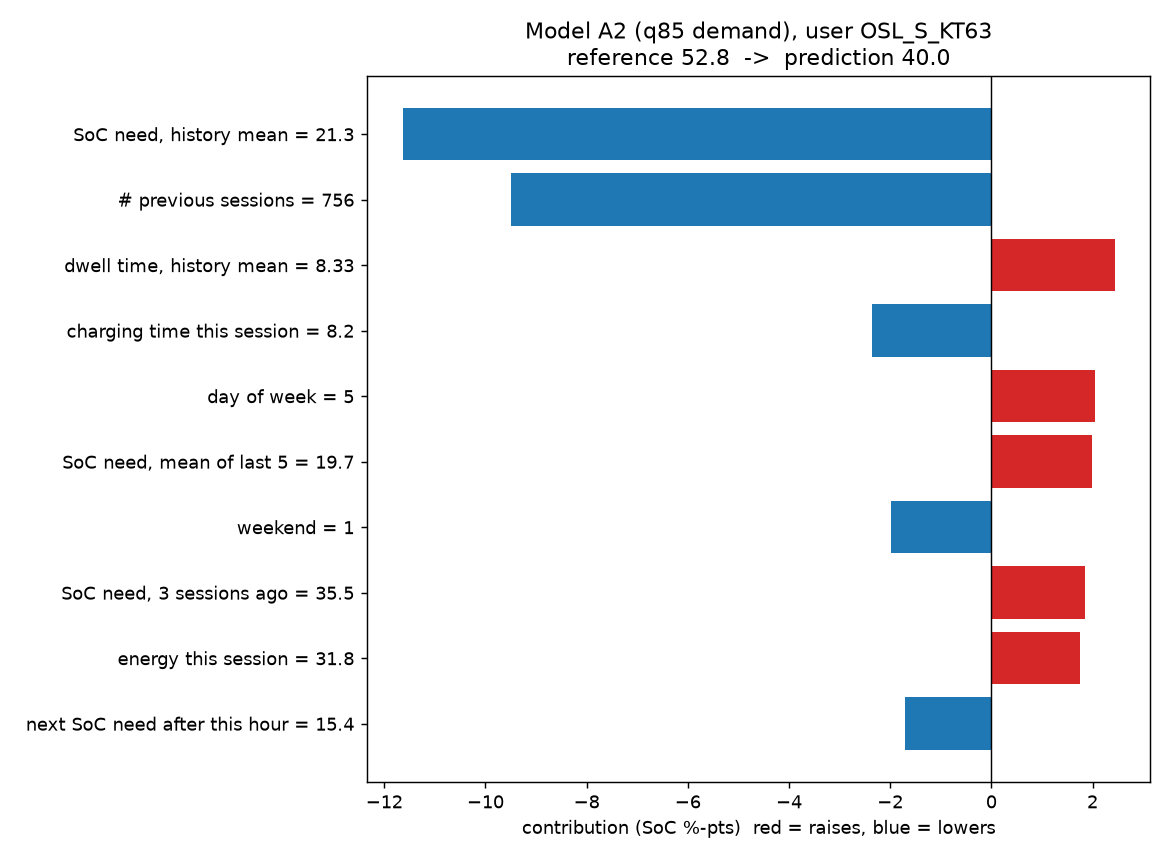

Predicted q85 demand: 40.0 SoC %-pts = reference 52.8 SoC %-pts + SoC need, history mean = 21.3 (-11.6), # previous sessions = 756 (-9.5), dwell time, history mean = 8.33 (+2.4), charging time this session = 8.2 (-2.4), day of week = 5 (+2.0), all other features (+6.2)
-> target SoC = clip(q85 demand + 15% reserve) = 55%   (additivity error 0.0e+00)



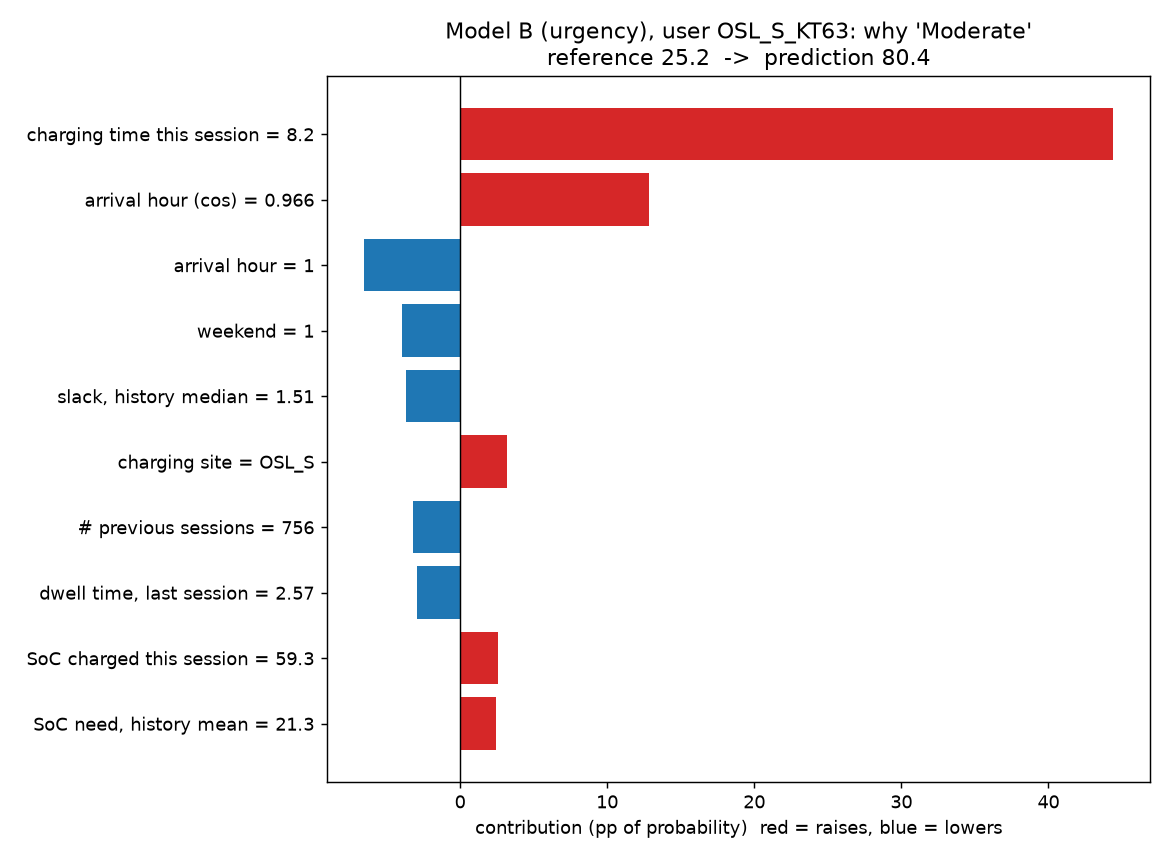

P(Moderate) = 80.4% = reference 25.2% + charging time this session = 8.2 (+44.4), arrival hour (cos) = 0.966 (+12.9), arrival hour = 1 (-6.5), weekend = 1 (-4.0), slack, history median = 1.51 (-3.6), all other features (+12.0)
class probabilities: {'Time-critical': '19%', 'Moderate': '80%', 'Flexible': '1%'}


In [26]:
def explain_one(R, tkey, uid, frame, method, background, nsamples=2000):
    """Exact-ish Kernel SHAP for a single session of one user (uses that user's own head)."""
    Rk = R[tkey]; spec, scaler, pred = Rk["spec"], Rk["scaler"], Rk["preds"][method]
    M = raw_matrix(frame.iloc[[0]], scaler); f = model_fn(pred, spec, scaler, uid)
    ex = shap.KernelExplainer(f, background)
    phi = _as_nPC(ex.shap_values(M, nsamples=nsamples, l1_reg=False, silent=True))[0]      # (P, C)
    return dict(phi=phi, base=np.atleast_1d(ex.expected_value).ravel(), fx=np.asarray(f(M)).ravel(),
                raw=M[0], players=shap_players(scaler), tkey=tkey)


def _val(E, i):
    v = E["raw"][i]
    if E["players"][i] == "location":
        return LOCATIONS[int(v)] if v >= 0 else "unknown"
    return "missing" if v <= MISSING / 2 else f"{v:.3g}"


def local_text(E, c=0, top=5, label=""):
    u = UNITS(E["tkey"]); unit = "%" if TASKS[E["tkey"]]["kind"] == "cls" else " SoC %-pts"
    phi = E["phi"][:, c] * u; order = np.argsort(-np.abs(phi))[:top]
    terms = ", ".join(f"{nice(E['players'][i])} = {_val(E, i)} ({phi[i]:+.1f})" for i in order)
    rest = phi.sum() - phi[order].sum()
    return (f"{label}{E['fx'][c] * u:.1f}{unit} = reference {E['base'][c] * u:.1f}{unit} + {terms}, "
            f"all other features ({rest:+.1f})")


def plot_local(E, c, title, path, top=10):
    u = UNITS(E["tkey"]); phi = E["phi"][:, c] * u
    order = np.argsort(-np.abs(phi))[:top][::-1]
    lab = [f"{nice(E['players'][i])} = {_val(E, i)}" for i in order]
    plt.figure(figsize=(9, 0.5 * top + 1.6))
    plt.barh(lab, phi[order], color=["#d62728" if v > 0 else "#1f77b4" for v in phi[order]])
    plt.axvline(0, color="k", lw=.8); plt.xlabel(f"contribution ({UNIT_LABEL(E['tkey'])})  red = raises, blue = lowers")
    plt.title(f"{title}\nreference {E['base'][c] * u:.1f}  ->  prediction {E['fx'][c] * u:.1f}")
    plt.tight_layout(); plt.savefig(path, dpi=130); plt.close()


# Model A2: why this target SoC?
EA = explain_one(R, "A2", uid, row, shap_method("A2"), SH["A2"]["bg"])
plot_local(EA, 0, f"Model A2 (q85 demand), user {uid}", f"{OUT_DIR}/module2_shap_local_A2.png")
display(Image(f"{OUT_DIR}/module2_shap_local_A2.png"))
print(local_text(EA, 0, label="Predicted q85 demand: "))
print(f"-> target SoC = clip(q85 demand + {RESERVE_PCT}% reserve) = "
      f"{np.clip(EA['fx'][0] + RESERVE_PCT, 30, SOC_MAX):.0f}%   (additivity error {abs(EA['base'][0] + EA['phi'][:, 0].sum() - EA['fx'][0]):.1e})\n")

# Model B: why this urgency class?
if uid in FRAMES["B"] and len(rowB):
    EB = explain_one(R, "B", uid, rowB, shap_method("B"), SH["B"]["bg"])
    cB = int(np.argmax(EB["fx"]))
    plot_local(EB, cB, f"Model B (urgency), user {uid}: why '{URG_NAMES[cB]}'", f"{OUT_DIR}/module2_shap_local_B.png")
    display(Image(f"{OUT_DIR}/module2_shap_local_B.png"))
    print(local_text(EB, cB, label=f"P({URG_NAMES[cB]}) = "))
    print("class probabilities:", {URG_NAMES[k]: f"{p * 100:.0f}%" for k, p in enumerate(EB["fx"])})

### 16.7 Federated SHAP – explaining without pooling user data
In 16.2 the reference sample was pooled from all clients – fine for development, but it needs raw rows in one place. Here each client explains **its own sessions against its own training rows** and sends the server only **one number per feature** (its mean |SHAP|) plus the number of sessions explained. The server takes the weighted average. The check below compares this privacy-preserving ranking with the pooled one.

Note: a client-local reference makes the baseline "this user's typical session", so values answer *"what is unusual about this session for this user?"* The *ranking* is what should agree with the pooled view.

In [27]:
def fed_aggregate(S):
    """Client side: mean |SHAP| vector + count. Server side: weighted average. Returns (importance, messages)."""
    msgs = {}
    for u in dict.fromkeys(S["uid"]):
        m = (S["uid"] == u)
        msgs[u] = (np.abs(S["phi"][m]).mean(0).mean(-1), int(m.sum()))      # what a client uploads
    W = sum(n for _, n in msgs.values())
    return pd.Series(sum(v * n for v, n in msgs.values()) / W, index=S["players"]), msgs


IMP_FED, CMP = {}, {}
for tk in SHAP_TASKS:
    t0 = time.time()
    Sf = shap_run(R, tk, shap_method(tk), bg="local", rows_per_client=SHAP_CFG.fed_rows_per_client,
                  n_bg=SHAP_CFG.fed_n_background, nsamples=SHAP_CFG.fed_nsamples, max_clients=SHAP_CFG.max_clients)
    IMP_FED[tk], msgs = fed_aggregate(Sf)
    a, b = IMP[tk], IMP_FED[tk]
    CMP[tk] = dict(clients=len(msgs), sessions=len(Sf["uid"]),
                   floats_uploaded_per_client=len(Sf["players"]) + 1,
                   spearman_rank_corr=round(float(a.corr(b, method="spearman")), 3),
                   top5_overlap=len(set(a.nlargest(5).index) & set(b.nlargest(5).index)),
                   top10_overlap=len(set(a.nlargest(10).index) & set(b.nlargest(10).index)))
    print(f"{tk}: federated SHAP done in {time.time() - t0:.0f}s")
pd.DataFrame(CMP).T

A1: federated SHAP done in 15s


A2: federated SHAP done in 15s


A3: federated SHAP done in 20s


B: federated SHAP done in 18s


,clients,sessions,floats_uploaded_per_client,spearman_rank_corr,top5_overlap,top10_overlap
A1,188.0,2271.0,36.0,0.301,2.0,5.0
A2,188.0,2271.0,36.0,0.484,1.0,5.0
A3,188.0,2271.0,36.0,0.357,3.0,5.0
B,209.0,2468.0,24.0,0.728,4.0,8.0


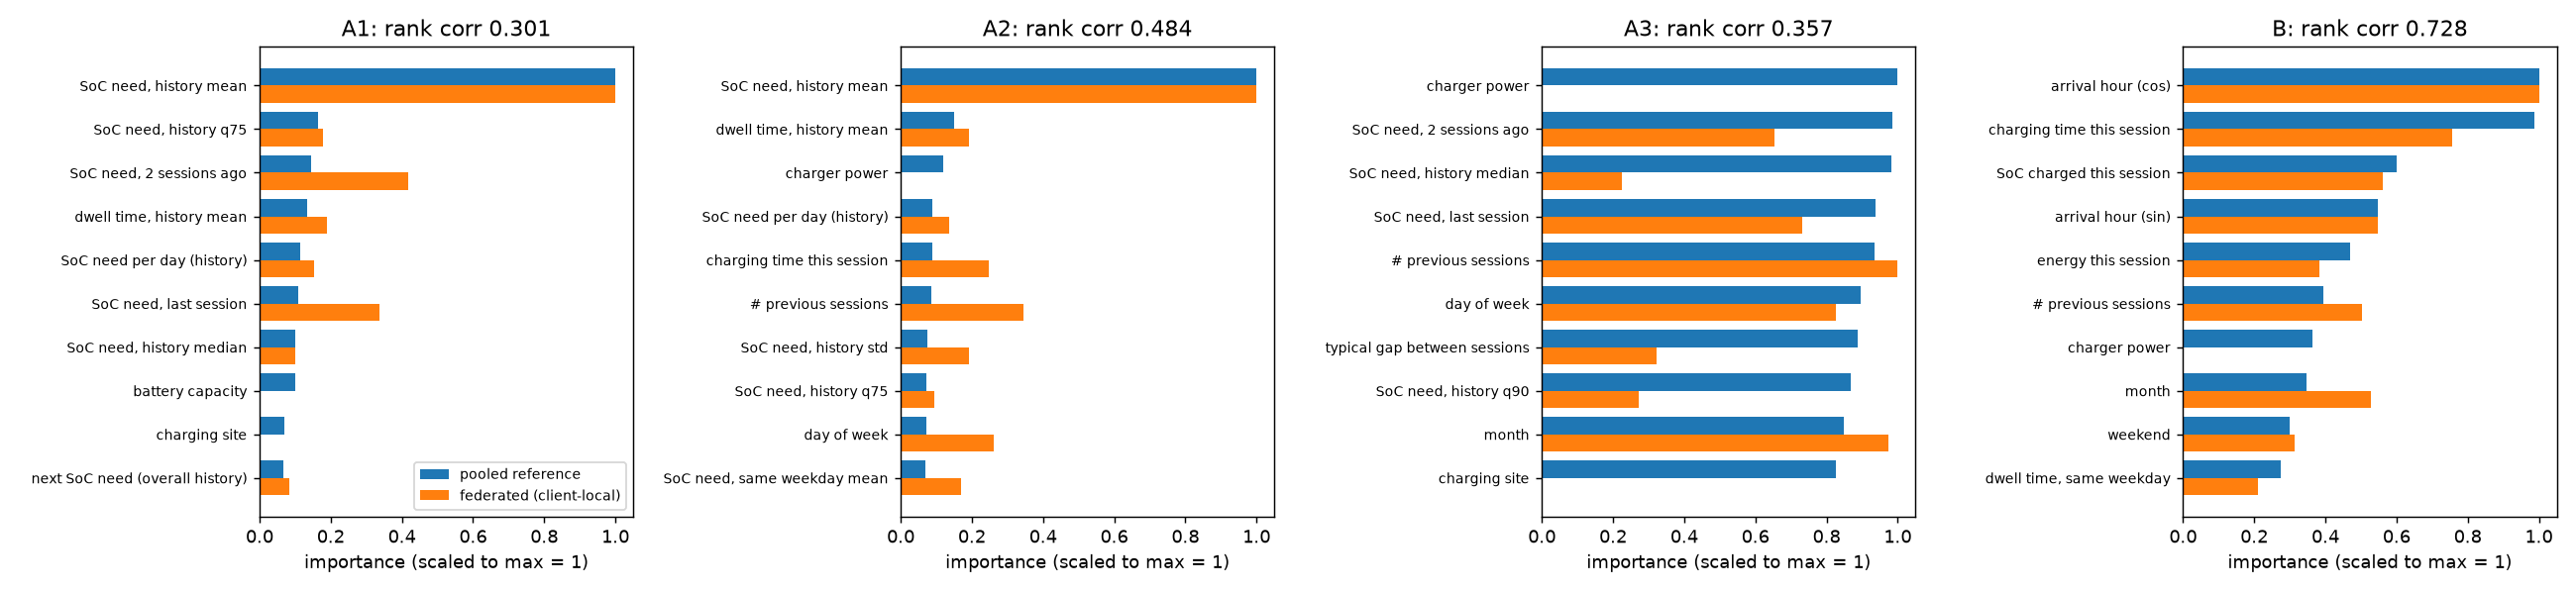

In [28]:
fig, ax = plt.subplots(1, 4, figsize=(20, 4.6))
for a, tk in zip(ax, SHAP_TASKS):
    top = IMP[tk].sort_values(ascending=False).head(10).index[::-1]
    y = np.arange(len(top))
    a.barh(y + .2, [IMP[tk][f] / IMP[tk].max() for f in top], .4, label="pooled reference")
    a.barh(y - .2, [IMP_FED[tk][f] / IMP_FED[tk].max() for f in top], .4, label="federated (client-local)")
    a.set_yticks(y); a.set_yticklabels([nice(f) for f in top], fontsize=8)
    a.set_title(f"{tk}: rank corr {CMP[tk]['spearman_rank_corr']}"); a.set_xlabel("importance (scaled to max = 1)")
ax[0].legend(fontsize=8); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/module2_shap_federated_vs_pooled.png", dpi=130); plt.close()
display(Image(f"{OUT_DIR}/module2_shap_federated_vs_pooled.png"))

### 16.8 Save the explanations
Writes one CSV with the feature ranking (pooled and federated, with family), plus the row-level SHAP values of the pooled run for further analysis. `explain_one` (16.6) is the function to call at recommendation time: it needs only the user's own model, the session's features and a small reference sample.

In [29]:
rows = []
for tk in SHAP_TASKS:
    for f in SH[tk]["players"]:
        rows.append(dict(task=tk, feature=f, label=nice(f), family=family(f),
                         mean_abs_shap_pooled=IMP[tk][f] * UNITS(tk), mean_abs_shap_federated=IMP_FED[tk][f] * UNITS(tk),
                         unit=UNIT_LABEL(tk)))
imp_df = pd.DataFrame(rows).sort_values(["task", "mean_abs_shap_pooled"], ascending=[True, False])
imp_df.to_csv(f"{OUT_DIR}/module2_shap_importance.csv", index=False)

for tk in SHAP_TASKS:
    S = SH[tk]; c = FOCUS[tk]
    cols = pd.DataFrame(S["phi"][:, :, c], columns=["shap_" + p for p in S["players"]])
    cols.insert(0, "user_id", S["uid"]); cols.insert(1, "baseline", S["base"][:, c]); cols.insert(2, "prediction", S["fx"][:, c])
    cols.to_csv(f"{OUT_DIR}/module2_shap_values_{tk}.csv", index=False)
print("saved:", sorted(f for f in os.listdir(OUT_DIR) if "shap" in f))
imp_df.groupby("task").head(3)

saved: ['module2_shap_beeswarm_A1.png', 'module2_shap_beeswarm_A2.png', 'module2_shap_beeswarm_A3.png', 'module2_shap_beeswarm_B.png', 'module2_shap_dependence_A2.png', 'module2_shap_dependence_B.png', 'module2_shap_families.png', 'module2_shap_federated_vs_pooled.png', 'module2_shap_importance.csv', 'module2_shap_importance.png', 'module2_shap_local_A2.png', 'module2_shap_local_B.png', 'module2_shap_values_A1.csv', 'module2_shap_values_A2.csv', 'module2_shap_values_A3.csv', 'module2_shap_values_B.csv']


,task,feature,label,family,mean_abs_shap_pooled,mean_abs_shap_federated,unit
17,A1,soc_hist_mean,"SoC need, history mean",Long-run user habits,11.272914,3.066486,SoC %-pts
31,A1,soc_hist_q75,"SoC need, history q75",Long-run user habits,1.853049,0.549094,SoC %-pts
15,A1,soc_lag2,"SoC need, 2 sessions ago",Recent sessions,1.636962,1.277259,SoC %-pts
52,A2,soc_hist_mean,"SoC need, history mean",Long-run user habits,12.037946,3.264534,SoC %-pts
56,A2,conn_hist_mean,"dwell time, history mean",Long-run user habits,1.791418,0.625374,SoC %-pts
42,A2,charging_power,charger power,Vehicle & current session,1.441163,0.000000,SoC %-pts
77,A3,charging_power,charger power,Vehicle & current session,1.426779,0.000000,pp of probability
85,A3,soc_lag2,"SoC need, 2 sessions ago",Recent sessions,1.407100,1.095078,pp of probability
100,A3,soc_hist_med,"SoC need, history median",Long-run user habits,1.399489,0.377987,pp of probability
110,B,hour_cos,arrival hour (cos),Time & calendar,7.582047,7.534313,pp of probability


## Notes & limitations
- **Simulation, not a deployment.** All clients run in one process. Moving to Flower or PyTorch means replacing `local_train` and the averaging step in `train_federated`; the data layer, metrics and saved-bundle format stay the same.
- **What the server sees:** weights and the aggregate scaler / class-count statistics. No secure aggregation or differential privacy is added; weights can still leak information about a user.
- **Split caveat:** with per-client time splits, a user's test sessions can be earlier in calendar time than other users' training sessions, so the global model may have seen other users' *future*. For a strict forecasting claim you would need all clients to be active over a common period, which this dataset does not offer.
- **Why not train+val refit:** Module 2 refits on train+validation; here the validation split chooses the best round, so test numbers are slightly conservative relative to Module 2.
- **Small validation comparison, no full search.** Rounds, local epochs, the server optimiser and the anchored target were compared on the validation split (see *Training improvements*); learning rate, width and `prox_mu` were not tuned.
- **Check the tables, not the method names.** The federated models now beat local-only training on every task and match the centralised MLP closely, but the centralised gradient-boosted trees (HGB) stay slightly better, and on A2 the coverage of the simple user-history q90 baseline is higher. A3 stays close to its baselines, as in Module 2.
- **FedPer for new users.** FedPer's average head serves unseen users poorly (A2 cold start). New users should use the FedAvg model until they have enough sessions for a personal head.
- **Model C and the decision layer stay as in Module 2.** Federating C would need sites or operators as clients (very few clients) for no measurable gain.
- **Cold start** covers users new to the federation, not users without history; true zero-history users fall back to the global model's population-level behaviour.
- **SHAP explains the model, not the world.** A large SHAP value means the *trained network relies on* that feature; it does not prove the feature causes a user's charging need. Many features are correlated (e.g. `soc_hist_mean`, `soc_hist_med`, `soc_hist_q90`), and Kernel SHAP splits credit between correlated features, so read the **feature families** (16.4) as the robust message and individual rankings within a family with care.
- **Sampling noise.** Kernel SHAP is a Monte-Carlo estimator: individual values wobble slightly between runs (the additivity identity always holds). Global rankings average over hundreds of sessions and are stable; raise `SHAP_CFG.nsamples` / `rows_per_client` for tighter plots.
- **Reference choice matters.** The pooled view explains against the population; the federated view against each user's own history. Both are shown in 16.7.
- **Privacy of explanations.** The federated variant uploads one aggregate number per feature per client, but – like the model weights – this is not differentially private. Local explanations (16.6) are computed on the device and never need to leave it.
- **Model C and the decision layer.** Model C is not part of this notebook; the decision layer has no trained parameters and is already transparent (travel / wait / charge / stress terms in `recommend_option`'s output).